<a href="https://colab.research.google.com/github/adryann-olivatti/IC_cozinhas_solidarias/blob/main/notebook_renda_cozinhas_solidarias_com_dados_conab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/adryann-olivatti/IC_cozinhas_solidarias/blob/main/notebook_renda_cozinhas_solidarias_corrigido_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Renda por Organização Fornecedora no PAA – Cozinhas Solidárias (CONAB, 2025)

**Pergunta central:** qual é a renda por organização fornecedora, categorizada por tipo — e essa renda se distribui de forma equitativa entre tipos de organização e entre territórios?

**Fontes de dados**
1. [Catálogo de dados (JSON)](https://github.com/TriangulosTecnologia/cozsolidarias/blob/main/public/dataset_catalogue.json)
2. [Portal de dados Cozinhas Solidárias](https://cozsolidarias.triangulos.tech/dados)
3. [Planilha CONAB – PAA 2025](https://docs.google.com/spreadsheets/d/1O_mmcnZ2QCBkA6juq_TzKYFv6KDwHsCU/edit)

**Roteiro**

| Seção | Conteúdo |
|---|---|
| 1–3 | Configuração, carga e limpeza dos dados |
| 4 | Renda por organização e por tipo |
| 5 | Concentração e desigualdade (Lorenz, Gini, Palma) |
| 6 | Perfil das organizações (variedade de produtos, povos tradicionais, mulheres) |
| 7 | Análise territorial (região, UF, per capita) e testes de robustez |
| 8 | **Verificação das afirmações** da discussão com os dados |
| 9 | **Análise crítica** dos resultados |
| 10 | Limitações, recomendações ligadas aos achados, conclusão e referências |

> **Nota metodológica:** "renda" aqui é o **valor contratado** nas propostas do PAA (coluna `VALOR (R\$)`), não o valor efetivamente pago. Cada linha da base é um produto dentro de uma proposta; a unidade de análise é a **organização proponente**, identificada pelo CNPJ.

## 1. Configuração

In [ ]:
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams.update({
    'figure.figsize': (11, 5.5),
    'figure.dpi': 110,
    'axes.titleweight': 'bold',
    'axes.titlesize': 12,
})
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

MIN_N = 10  # nº mínimo de organizações para interpretar Gini/Lorenz de um grupo


def brl(x, casas=2):
    """Formata número como moeda brasileira: R$ 1.234,56."""
    return 'R$ ' + f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def mi(x):
    """Formata como R$ X,X mi."""
    return 'R$ ' + f'{x / 1e6:,.1f}'.replace('.', ',') + ' mi'


def sem_acento(s):
    return ''.join(c for c in unicodedata.normalize('NFKD', str(s)) if not unicodedata.combining(c))


def mostrar(d, brl_cols=(), pct_cols=(), dec_cols=(), x_cols=()):
    """Exibe uma cópia do DataFrame com formatação legível (sem alterar os números originais)."""
    d = d.copy()
    for c in brl_cols:
        d[c] = d[c].map(brl)
    for c in pct_cols:
        d[c] = d[c].map('{:.1f}%'.format)
    for c in dec_cols:
        d[c] = d[c].map('{:.3f}'.format)
    for c in x_cols:
        d[c] = d[c].map('{:.2f}x'.format)
    display(d)

## 2. Carga dos dados da CONAB
A planilha é baixada diretamente do Google Sheets; a aba e a linha de cabeçalho são localizadas automaticamente.

In [ ]:
import glob

# Usa o arquivo local da CONAB se ele estiver na pasta do notebook (ex.: enviado ao Colab);
# caso contrário, baixa a planilha pública do Google Sheets.
locais = glob.glob('*CONAB*PAA*.xlsx') + glob.glob('/mnt/user-data/uploads/*CONAB*PAA*.xlsx')
SHEET_ID = '1O_mmcnZ2QCBkA6juq_TzKYFv6KDwHsCU'
FONTE = locais[0] if locais else f'https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=xlsx'
print('Fonte dos dados:', FONTE)

xls = pd.ExcelFile(FONTE)
print('Abas encontradas:', xls.sheet_names)


def ler_aba(xls, palavra_aba, chave_cabecalho):
    """Lê a aba cujo nome contém `palavra_aba`, localizando a linha de cabeçalho pela coluna `chave_cabecalho`."""
    aba = next(a for a in xls.sheet_names if palavra_aba in a.upper())
    bruto = pd.read_excel(xls, sheet_name=aba, header=None)
    for i in range(min(20, len(bruto))):
        if any(chave_cabecalho in str(v).upper() for v in bruto.iloc[i]):
            return aba, i, pd.read_excel(xls, sheet_name=aba, skiprows=i)
    raise ValueError(f'Cabeçalho não encontrado na aba {aba}')


# PRODUTOS: uma linha por produto dentro de cada proposta (base principal de valores)
aba, linha_cab, df_raw = ler_aba(xls, 'PRODUTOS', 'PROPONENTE')
print(f"\nPRODUTOS  -> aba '{aba}', cabeçalho na linha {linha_cab + 1}: {df_raw.shape[0]} linhas × {df_raw.shape[1]} colunas")

# CONTRATAÇÕES 2025: uma linha por proposta, com nº de fornecedores, mulheres, beneficiários e forma jurídica
aba_c, linha_c, contr_raw = ler_aba(xls, 'CONTRATA', 'CNPJ')
print(f"CONTRATAÇÕES -> aba '{aba_c}', cabeçalho na linha {linha_c + 1}: {contr_raw.shape[0]} linhas × {contr_raw.shape[1]} colunas")
df_raw.head()

Fonte dos dados: DADOS_CONAB_PAA_2025.xlsx
Abas encontradas: ['DADOS', 'PRODUTOS', 'CONTRATAÇÕES 2025', 'UNIDADES RECEBEDORAS']

PRODUTOS  -> aba 'PRODUTOS', cabeçalho na linha 10: 1996 linhas × 20 colunas
CONTRATAÇÕES -> aba 'CONTRATAÇÕES 2025', cabeçalho na linha 11: 280 linhas × 30 colunas


,ANO ORÇAMENTO,MECANISMO,MECANISMO RESUMO,RECURSO,UF CONAB,REGIÃO,TPAF,IBGE,MUNICÍPIO,NOME PROPONENTE,CNPJ PROPONENTE,TIPO DE ORG,ORG DE MULHERES,PRODUTO,Categoria produto,CLASSIFICAÇÃO,VALOR (R$),QUANTIDADE (KG),ORGÂNICO (SIM),Preço
0,2025.0,MDS,CDS/COZINHAS,COZINHAS,AC,NORTE,AC/2025/02/0208,1200104.0,BRASILÉIA,COOPERATIVA DE PRODUTORES AGROFLORESTAIS E AGRICULTORES FAMILIARES DE BRASILEIA,09.197.432/0001-09,AGRICULTOR FAMILIAR,NaN,FEIJAO,GRÃOS E OLEAGINOSAS,NÃO INFORMADO,15000.0,1250.0,NaN,12.0
1,2025.0,MDS,CDS/COZINHAS,COZINHAS,AC,NORTE,AC/2025/02/0210,1200807.0,PORTO ACRE,"Cooperativa dos Produtores, Extrativistas de Agricultura Famíliar do Caquetá - COOPERATIVA SONHO MEU",18.020.228/0001-09,AGRICULTOR FAMILIAR,NaN,ABOBORA,HORTIGRANJEIROS,NÃO INFORMADO,7500.0,1000.0,NaN,7.5
2,2025.0,MDS,CDS/COZINHAS,COZINHAS,AC,NORTE,AC/2025/02/0210,1200807.0,PORTO ACRE,"Cooperativa dos Produtores, Extrativistas de Agricultura Famíliar do Caquetá - COOPERATIVA SONHO MEU",18.020.228/0001-09,AGRICULTOR FAMILIAR,NaN,COUVE,HORTIGRANJEIROS,NÃO INFORMADO,8750.0,350.0,NaN,25.0
3,2025.0,MDS,CDS/COZINHAS,COZINHAS,AC,NORTE,AC/2025/02/0210,1200807.0,PORTO ACRE,"Cooperativa dos Produtores, Extrativistas de Agricultura Famíliar do Caquetá - COOPERATIVA SONHO MEU",18.020.228/0001-09,AGRICULTOR FAMILIAR,NaN,FARINHA DE MANDIOCA,PROCESSADOS,NÃO INFORMADO,29250.0,3900.0,NaN,7.5
4,2025.0,MDS,CDS/COZINHAS,COZINHAS,AC,NORTE,AC/2025/02/0210,1200807.0,PORTO ACRE,"Cooperativa dos Produtores, Extrativistas de Agricultura Famíliar do Caquetá - COOPERATIVA SONHO MEU",18.020.228/0001-09,AGRICULTOR FAMILIAR,NaN,FECULA DE MANDIOCA,PROCESSADOS,NÃO INFORMADO,14960.0,1360.0,NaN,11.0


## 3. Limpeza e padronização
Três problemas na base bruta precisam ser tratados antes de qualquer cálculo:

1. **Linha de total:** a planilha contém uma linha sem CNPJ e sem tipo cujo valor é a soma de todas as demais. Se mantida, ela vira uma "organização" fictícia que dobra o total e distorce todos os gráficos. A célula abaixo mostra a verificação.
2. **Categorias duplicadas:** "Agricultor familiar" e "Agricultores familiares" (e equivalentes para assentados, pescadores e povos indígenas) aparecem como tipos separados. Elas são unificadas.
3. **Identificação das organizações:** o nome da proponente tem resíduos de codificação (ex.: `_X0083_`), então o **CNPJ** é usado como identificador.

In [ ]:
COLUNAS = ['TIPO DE ORG', 'NOME PROPONENTE', 'CNPJ PROPONENTE', 'VALOR (R$)', 'UF CONAB',
           'PRODUTO', 'Categoria produto', 'ORG DE MULHERES', 'TPAF']
df = df_raw[[c for c in COLUNAS if c in df_raw.columns]].copy()
for c in COLUNAS:
    if c not in df.columns:
        df[c] = np.nan


def limpar_valor(v):
    if pd.isna(v):
        return 0.0
    if isinstance(v, (int, float, np.number)):
        return float(v)
    try:
        return float(str(v).replace('R$', '').replace('.', '').replace(',', '.').strip())
    except ValueError:
        return 0.0


df['VALOR'] = df['VALOR (R$)'].apply(limpar_valor)

# --- 3.1 Remoção de linhas que não são contratações (ex.: linha de TOTAL da planilha) ---
sem_id = df['CNPJ PROPONENTE'].isna() | df['TIPO DE ORG'].isna()
removidas = df[sem_id]
total_bruto = df['VALOR'].sum()
df = df[~sem_id & (df['VALOR'] > 0)].copy()
total_limpo = df['VALOR'].sum()

print(f'Linhas removidas (sem CNPJ/tipo): {len(removidas)} | valor somado nelas: {brl(removidas["VALOR"].sum())}')
print(f'Total antes da limpeza : {brl(total_bruto)}')
print(f'Total após a limpeza   : {brl(total_limpo)}')
print(f'A linha removida equivale a {removidas["VALOR"].sum() / total_limpo:.1%} do total limpo '
      f'-> {"é uma linha de total (dupla contagem)" if abs(removidas["VALOR"].sum() / total_limpo - 1) < 0.01 else "verificar"}')


# --- 3.2 Padronização das categorias (singular/plural e acentos viravam categorias distintas) ---
def padronizar_tipo(t):
    s = sem_acento(t).upper().strip()
    if 'AGRICULTOR' in s:
        return 'Agricultores familiares'
    if 'ASSENTAD' in s:
        return 'Assentados da reforma agrária'
    if 'PESCADOR' in s:
        return 'Pescadores artesanais'
    if 'QUILOMBOLA' in s:
        return 'Quilombolas'
    if 'INDIGENA' in s:
        return 'Povos indígenas'
    if 'EXTRATIV' in s:
        return 'Agroextrativistas'
    return s.title()


print('\nTipos originais ->', sorted(df['TIPO DE ORG'].astype(str).unique()))
df['TIPO'] = df['TIPO DE ORG'].map(padronizar_tipo)
print('Tipos padronizados ->', sorted(df['TIPO'].unique()))


# --- 3.3 Identificação das organizações (CNPJ), nomes e território ---
def limpar_nome(n):
    n = re.sub(r'_X[0-9A-Fa-f]{4}_', '', str(n))   # resíduos de codificação da planilha
    return re.sub(r'\s+', ' ', n).strip().upper()


df['ORG_ID'] = df['CNPJ PROPONENTE'].astype(str).str.replace(r'\D', '', regex=True)
df['NOME'] = df['NOME PROPONENTE'].map(limpar_nome)
df['COOPERATIVA'] = df['NOME'].str.contains('COOPERATIVA', na=False)

UF_REGIAO = {
    **dict.fromkeys(['AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO'], 'Norte'),
    **dict.fromkeys(['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'], 'Nordeste'),
    **dict.fromkeys(['DF', 'GO', 'MT', 'MS'], 'Centro-Oeste'),
    **dict.fromkeys(['ES', 'MG', 'RJ', 'SP'], 'Sudeste'),
    **dict.fromkeys(['PR', 'RS', 'SC'], 'Sul'),
}
df['UF'] = df['UF CONAB'].astype(str).str.upper().str.strip()
df['REGIAO'] = df['UF'].map(UF_REGIAO)
print(f'\nLinhas sem região identificada: {df["REGIAO"].isna().sum()}')

# Mulheres: considera sinalizada qualquer célula preenchida que não seja uma negação
neg = {'NAO', 'N', '0', 'NAN', '', 'NONE'}
txt = df['ORG DE MULHERES'].map(lambda v: sem_acento(v).upper().strip())
df['ORG_MULHERES'] = df['ORG DE MULHERES'].notna() & ~txt.isin(neg)

print(f'\nBase final: {len(df)} linhas de contratação | {df["ORG_ID"].nunique()} organizações | {brl(df["VALOR"].sum())}')

Linhas removidas (sem CNPJ/tipo): 1 | valor somado nelas: R$ 119.207.476,10
Total antes da limpeza : R$ 238.414.952,24
Total após a limpeza   : R$ 119.207.476,14
A linha removida equivale a 100.0% do total limpo -> é uma linha de total (dupla contagem)

Tipos originais -> ['AGRICULTOR FAMILIAR', 'AGRICULTORES FAMILIARES ', 'AGROEXTRATIVISTA', 'ASSENTADO DA REFORMA AGRÁRIA', 'ASSENTADOS DA REFORMA AGRARIA', 'COMUNIDADE INDÍGENA', 'PESCADOR ARTESANAL', 'PESCADORES ARTESANAIS', 'POVOS INDÍGENAS', 'QUILOMBOLA']
Tipos padronizados -> ['Agricultores familiares', 'Agroextrativistas', 'Assentados da reforma agrária', 'Pescadores artesanais', 'Povos indígenas', 'Quilombolas']

Linhas sem região identificada: 0

Base final: 1995 linhas de contratação | 240 organizações | R$ 119.207.476,14


### 3.4 Aba CONTRATAÇÕES: reconciliação e dados de fornecedores
A aba **CONTRATAÇÕES 2025** tem uma linha por proposta e traz o que a aba PRODUTOS não tem: nº de fornecedores individuais, nº de mulheres, povos tradicionais, beneficiários atendidos e a **forma jurídica** oficial (cooperativa ou associação). Ela é conferida contra a aba PRODUTOS (mesmo valor total, mesmos CNPJs) e usada nas seções 6.3, 7 e 8.

In [ ]:
# Tabela de propostas (aba CONTRATAÇÕES): fornecedores individuais, mulheres, beneficiários e forma jurídica
contr = contr_raw.copy()
contr.columns = [re.sub(r'\s+', ' ', str(c)).strip() for c in contr.columns]
contr = contr[contr['CNPJ'].notna()].copy()


def achar(palavra):
    return next(c for c in contr.columns if palavra in c.upper())


def so_digitos(v):
    return str(int(v)) if isinstance(v, (int, float, np.number)) else re.sub(r'\D', '', str(v))


contr['ORG_ID'] = contr['CNPJ'].map(so_digitos).str.zfill(14)   # a planilha perdeu zeros à esquerda do CNPJ
contr['UF'] = contr['UF CONAB'].astype(str).str.upper().str.strip()
contr['REGIAO'] = contr['UF'].map(UF_REGIAO)
contr = contr.rename(columns={
    achar('VALOR TOTAL'): 'VALOR_PREVISTO',
    achar('FORNECEDORES PREVISTO'): 'FORNECEDORES',
    achar('BENEFICIÁRIOS CONSUMIDORES'): 'BENEFICIARIOS',
    'Nº Mulheres': 'MULHERES', 'NºJuventude': 'JUVENTUDE', 'NºPCT': 'PCT', 'NºAssentado': 'ASSENTADOS',
    'NºAgroextrativista': 'AGROEXTRATIVISTAS', 'Nº Povos Indigena': 'INDIGENAS',
    'NºPescador Artesanal': 'PESCADORES', 'Nº Quilombolas': 'QUILOMBOLAS',
})
NUM = ['VALOR_PREVISTO', 'FORNECEDORES', 'BENEFICIARIOS', 'MULHERES', 'JUVENTUDE', 'PCT', 'ASSENTADOS',
       'AGROEXTRATIVISTAS', 'INDIGENAS', 'PESCADORES', 'QUILOMBOLAS']
for c in NUM:
    contr[c] = pd.to_numeric(contr[c], errors='coerce').fillna(0)

# Reconciliação entre as duas abas
print(f'Propostas: {len(contr)} | organizações (CNPJ): {contr["ORG_ID"].nunique()}')
print(f'Valor total na aba CONTRATAÇÕES: {brl(contr["VALOR_PREVISTO"].sum())} | na aba PRODUTOS (limpa): {brl(df["VALOR"].sum())}')
print(f'CNPJs presentes nas duas abas: {len(set(contr["ORG_ID"]) & set(df["ORG_ID"]))} de {df["ORG_ID"].nunique()}')

# Forma jurídica oficial (cooperativa x associação), no lugar do palpite pelo nome
forma = contr.groupby('ORG_ID')['TIPO ORGANIZAÇÃO'].first().astype(str).str.upper()
df['FORMA'] = df['ORG_ID'].map(forma)
df['COOPERATIVA'] = np.where(df['FORMA'].notna(), df['FORMA'].str.contains('COOPERATIVA', na=False), df['COOPERATIVA'])
df['COOPERATIVA'] = df['COOPERATIVA'].astype(bool)
print('\nForma jurídica das organizações:')
print(contr.drop_duplicates('ORG_ID')['TIPO ORGANIZAÇÃO'].value_counts().to_string())

Propostas: 280 | organizações (CNPJ): 240
Valor total na aba CONTRATAÇÕES: R$ 119.207.476,14 | na aba PRODUTOS (limpa): R$ 119.207.476,14
CNPJs presentes nas duas abas: 240 de 240

Forma jurídica das organizações:
TIPO ORGANIZAÇÃO
COOPERATIVA    128
ASSOCIAÇÃO     112


## 4. Renda por organização e por tipo

### 4.1 Renda por organização

In [ ]:
# Uma linha por organização (CNPJ) dentro de cada tipo
renda_org = (
    df.groupby(['TIPO', 'ORG_ID'])
      .agg(NOME=('NOME', 'first'),
           RENDA=('VALOR', 'sum'),
           ITENS=('VALOR', 'size'),
           PRODUTOS_DISTINTOS=('PRODUTO', 'nunique'),
           PROPOSTAS=('TPAF', 'nunique'))
      .reset_index()
)
renda_org['VALOR_MEDIO_ITEM'] = renda_org['RENDA'] / renda_org['ITENS']

print(f'{len(renda_org)} organizações. Abaixo: as 5 de maior renda em cada tipo '
      '(tabela completa salva em renda_por_organizacao.csv).')
top5 = (renda_org.sort_values(['TIPO', 'RENDA'], ascending=[True, False])
                 .groupby('TIPO').head(5)[['TIPO', 'NOME', 'RENDA', 'ITENS', 'VALOR_MEDIO_ITEM']])
mostrar(top5, brl_cols=['RENDA', 'VALOR_MEDIO_ITEM'])
renda_org.sort_values(['TIPO', 'RENDA'], ascending=[True, False]).to_csv('renda_por_organizacao.csv', index=False)

244 organizações. Abaixo: as 5 de maior renda em cada tipo (tabela completa salva em renda_por_organizacao.csv).


,TIPO,NOME,RENDA,ITENS,VALOR_MEDIO_ITEM
3,Agricultores familiares,COOP DOS TRABALHADORES ASSENT REGIAO PORTO ALEGRE LTDA.,"R$ 4.080.049,80",3,"R$ 1.360.016,60"
33,Agricultores familiares,COOPERATIVA MISTA DE PRODUÇÃO E COMERCIALIZAÇÃO CAMPONESA DO RIO GRANDE DO SUL - CPC DO RG,"R$ 2.995.780,00",2,"R$ 1.497.890,00"
160,Agricultores familiares,COOPERATIVA DOS SUINOCULTORES DO CAI SUPERIOR,"R$ 2.695.789,70",6,"R$ 449.298,28"
40,Agricultores familiares,COOPERATIVA DE DESENVOLVIMENTO REGIONAL LTDA,"R$ 2.059.917,55",14,"R$ 147.136,97"
134,Agricultores familiares,ASSOCIAÇÃO DOS AQUICULTORES E PESCADORES ARTESANAIS DO RIO DE JANEIRO,"R$ 1.530.000,00",2,"R$ 765.000,00"
161,Agroextrativistas,ASSOCIAÇÃO DE MORADORES DA RESERVA EXTRATIVISTA DO RIO IRIRI,"R$ 788.175,40",72,"R$ 10.946,88"
198,Assentados da reforma agrária,COOPERATIVA MISTA DE COMERCIALIZACAO E TRABALHO GRANO LTDA,"R$ 2.097.046,00",2,"R$ 1.048.523,00"
177,Assentados da reforma agrária,"COOPERATIVA MISTA DE PRODUÇÃO, COMERCIALIZAÇÃO E SERVIÇOS DA TERRA","R$ 1.779.045,76",1,"R$ 1.779.045,76"
191,Assentados da reforma agrária,COOPERATIVA DE PRODUCAO E SUSTENTABILIDADE DA AGRICULTURA FAMILIAR,"R$ 1.649.822,58",2,"R$ 824.911,29"
189,Assentados da reforma agrária,COOPERATIVA DOS TRABALHADORES DA REFORMA AGRARIA TERRA LIVRE LTDA,"R$ 1.499.107,26",21,"R$ 71.386,06"


### 4.2 Resumo por tipo de organização

,TIPO,RENDA_TOTAL,N_ORGS,MEDIA,MEDIANA,PRODUTOS_POR_ORG,PCT_RENDA,PCT_ORGS
0,Agricultores familiares,"R$ 75.018.432,24",161,"R$ 465.953,00","R$ 219.998,80",7.925,62.9%,66.0%
1,Assentados da reforma agrária,"R$ 32.245.273,73",61,"R$ 528.611,04","R$ 359.996,08",5.639,27.0%,25.0%
2,Pescadores artesanais,"R$ 9.704.602,38",14,"R$ 693.185,88","R$ 593.744,58",3.786,8.1%,5.7%
3,Agroextrativistas,"R$ 788.175,40",1,"R$ 788.175,40","R$ 788.175,40",71.000,0.7%,0.4%
4,Quilombolas,"R$ 725.524,25",4,"R$ 181.381,06","R$ 109.967,12",7.750,0.6%,1.6%
5,Povos indígenas,"R$ 725.468,14",3,"R$ 241.822,71","R$ 259.997,74",7.333,0.6%,1.2%


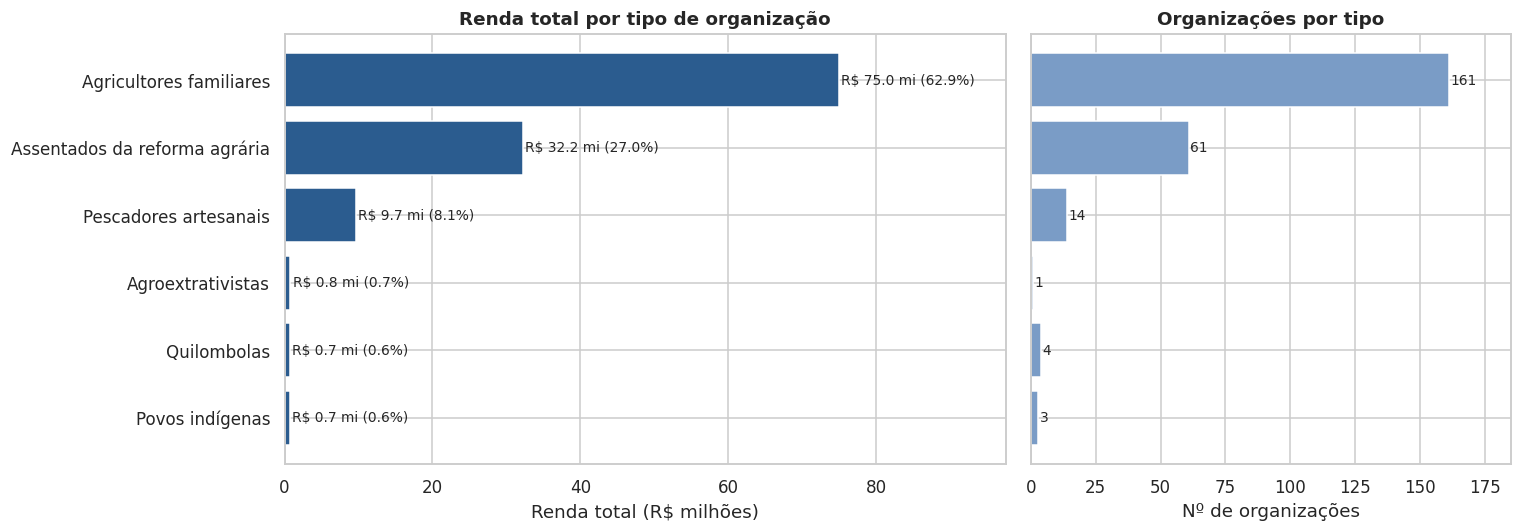

In [ ]:
resumo = (
    renda_org.groupby('TIPO')
             .agg(RENDA_TOTAL=('RENDA', 'sum'),
                  N_ORGS=('ORG_ID', 'nunique'),
                  MEDIA=('RENDA', 'mean'),
                  MEDIANA=('RENDA', 'median'),
                  PRODUTOS_POR_ORG=('PRODUTOS_DISTINTOS', 'mean'))
             .reset_index()
)
resumo['PCT_RENDA'] = resumo['RENDA_TOTAL'] / resumo['RENDA_TOTAL'].sum() * 100
resumo['PCT_ORGS'] = resumo['N_ORGS'] / resumo['N_ORGS'].sum() * 100
resumo = resumo.sort_values('RENDA_TOTAL', ascending=False).reset_index(drop=True)

mostrar(resumo, brl_cols=['RENDA_TOTAL', 'MEDIA', 'MEDIANA'], pct_cols=['PCT_RENDA', 'PCT_ORGS'],
        dec_cols=['PRODUTOS_POR_ORG'])

# Gráfico 1 – renda total e nº de organizações por tipo
ordem = resumo.sort_values('RENDA_TOTAL')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [3, 2]}, sharey=True)

b = a1.barh(ordem['TIPO'], ordem['RENDA_TOTAL'] / 1e6, color='#2b5c8f')
for rect, (_, r) in zip(b, ordem.iterrows()):
    a1.text(rect.get_width() + 0.3, rect.get_y() + rect.get_height() / 2,
            f"R$ {r.RENDA_TOTAL / 1e6:,.1f} mi ({r.PCT_RENDA:.1f}%)", va='center', fontsize=9)
a1.set_xlim(0, ordem['RENDA_TOTAL'].max() / 1e6 * 1.3)
a1.set_xlabel('Renda total (R$ milhões)')
a1.set_title('Renda total por tipo de organização')

b = a2.barh(ordem['TIPO'], ordem['N_ORGS'], color='#7a9cc6')
for rect in b:
    a2.text(rect.get_width() + 0.5, rect.get_y() + rect.get_height() / 2, int(rect.get_width()), va='center', fontsize=9)
a2.set_xlim(0, ordem['N_ORGS'].max() * 1.15)
a2.set_xlabel('Nº de organizações')
a2.set_title('Organizações por tipo')
plt.tight_layout()
plt.show()

**Análise do gráfico.** *O que mostra:* agricultores familiares concentram 62,9% da renda (R\$ 75,0 mi, 161 organizações), seguidos por assentados (27,0%; R\$ 32,2 mi; 61) e pescadores artesanais (8,1%; R\$ 9,7 mi; 14). Agroextrativistas, quilombolas e indígenas somam 1,9% da renda, com 1, 4 e 3 organizações.

*Leitura crítica:* (1) o volume está concentrado em tipos grandes em número de organizações: o painel da direita praticamente repete o da esquerda. (2) Mas **volume do tipo não é renda por organização**: os pescadores têm a maior média entre os tipos com n ≥ 10 (R\$ 693 mil), enquanto os agricultores familiares, dominantes no total, têm média de R\$ 466 mil, abaixo da média geral (R\$ 489 mil). (3) Três dos seis tipos têm menos de 10 organizações; o agroextrativista é **uma única organização** (Reserva Extrativista do Rio Iriri, R\$ 788 mil), então não há "perfil do tipo" para descrever.

### 4.3 Média vs. mediana
Quando a média fica muito acima da mediana, algumas organizações grandes estão "puxando" a média do grupo para cima.

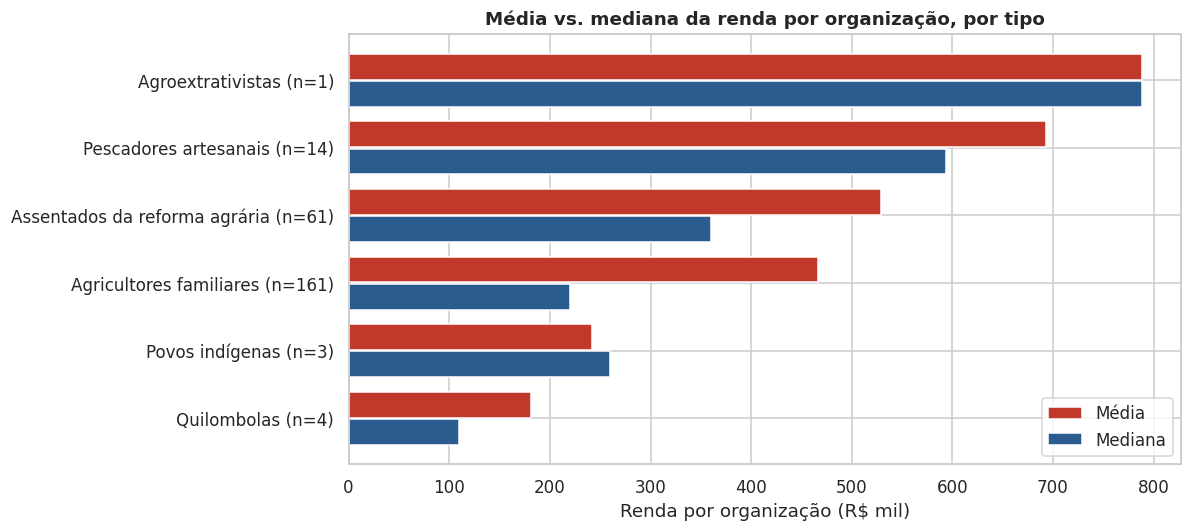

,TIPO,N_ORGS,RAZAO_MEDIA_MEDIANA
0,Agricultores familiares,161,2.12x
4,Quilombolas,4,1.65x
1,Assentados da reforma agrária,61,1.47x
2,Pescadores artesanais,14,1.17x
3,Agroextrativistas,1,1.00x
5,Povos indígenas,3,0.93x


In [ ]:
# Gráfico 2 – média vs. mediana por organização (a média acima da mediana indica influência de poucas organizações grandes)
d = resumo.sort_values('MEDIA')
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(y + 0.2, d['MEDIA'] / 1e3, height=0.38, color='#c0392b', label='Média')
ax.barh(y - 0.2, d['MEDIANA'] / 1e3, height=0.38, color='#2b5c8f', label='Mediana')
ax.set_yticks(y)
ax.set_yticklabels([f'{t} (n={n})' for t, n in zip(d['TIPO'], d['N_ORGS'])])
ax.set_xlabel('Renda por organização (R$ mil)')
ax.set_title('Média vs. mediana da renda por organização, por tipo')
ax.legend()
plt.tight_layout()
plt.show()

d = resumo.assign(RAZAO_MEDIA_MEDIANA=resumo['MEDIA'] / resumo['MEDIANA'])[['TIPO', 'N_ORGS', 'RAZAO_MEDIA_MEDIANA']]
mostrar(d.sort_values('RAZAO_MEDIA_MEDIANA', ascending=False), x_cols=['RAZAO_MEDIA_MEDIANA'])

**Análise do gráfico.** *O que mostra:* a média supera a mediana em quase todos os tipos. A razão é de 2,12x para agricultores familiares (média R\$ 466 mil vs. mediana R\$ 220 mil), 1,47x para assentados e 1,17x para pescadores.

*Leitura crítica:* nos agricultores familiares, metade das organizações recebeu até R\$ 220 mil, menos da metade da "média do tipo"; poucas cooperativas grandes puxam a média. Por isso a **mediana é a medida mais honesta** para comparar tipos e regiões: com ela, os agricultores familiares (R\$ 220 mil) ficam atrás dos assentados (R\$ 360 mil) e dos pescadores (R\$ 594 mil), uma ordem que a média esconde em parte. As razões de quilombolas (1,65x), indígenas (0,93x) e agroextrativistas (1,00x) não são interpretáveis, pois vêm de 4, 3 e 1 organizações.

## 5. Concentração e desigualdade de renda

**Curva de Lorenz:** ordena as organizações da menor para a maior renda e mostra, no eixo Y, a fração acumulada da renda; quanto mais a curva se afasta da diagonal (igualdade perfeita), maior a concentração.

**Índice de Gini:** é o dobro da área entre a diagonal e a curva; vai de 0 (igualdade) a 1 (uma única organização com toda a renda).

$$G = \frac{2\sum_{i=1}^{n} i\,y_i}{n\sum_{i=1}^{n} y_i} - \frac{n+1}{n}, \qquad y_1 \le y_2 \le \dots \le y_n$$

**Razão de Palma:** renda do top 10% ÷ renda dos 40% menores. Ex.: Palma = 4 significa que o topo recebe 4 vezes o que a base recebe.

> Grupos com menos de 10 organizações (`MIN_N`) têm Gini e Palma instáveis; aparecem nas tabelas, mas ficam de fora das curvas de Lorenz.

In [ ]:
def gini(v):
    y = np.sort(np.asarray(v, dtype=float))
    n = len(y)
    return 2 * np.sum(np.arange(1, n + 1) * y) / (n * y.sum()) - (n + 1) / n


def lorenz(v):
    y = np.sort(np.asarray(v, dtype=float))
    acum = np.insert(np.cumsum(y) / y.sum(), 0, 0)
    return np.linspace(0, 1, len(acum)), acum


def parcela_topo(v, frac):
    y = np.sort(np.asarray(v, dtype=float))[::-1]
    return y[:max(1, int(round(len(y) * frac)))].sum() / y.sum()


def parcela_base(v, frac):
    y = np.sort(np.asarray(v, dtype=float))
    return y[:max(1, int(round(len(y) * frac)))].sum() / y.sum()


def indicadores(v):
    v = np.asarray(v, dtype=float)
    top10, bot40 = parcela_topo(v, .10) * 100, parcela_base(v, .40) * 100
    return {'N_ORGS': len(v), 'RENDA_TOTAL': v.sum(), 'GINI': gini(v) if len(v) > 1 else np.nan,
            'TOP10_%': top10, 'BASE40_%': bot40, 'PALMA': top10 / bot40}


linhas = [{'TIPO': 'TOTAL GERAL', **indicadores(renda_org['RENDA'])}]
linhas += [{'TIPO': t, **indicadores(g['RENDA'])} for t, g in renda_org.groupby('TIPO')]
conc = pd.DataFrame(linhas)
conc['CONFIAVEL'] = np.where(conc['N_ORGS'] >= MIN_N, 'sim', f'não (n<{MIN_N})')
conc = pd.concat([conc.iloc[:1], conc.iloc[1:].sort_values('GINI', ascending=False)], ignore_index=True)

mostrar(conc, brl_cols=['RENDA_TOTAL'], pct_cols=['TOP10_%', 'BASE40_%'], dec_cols=['GINI'], x_cols=['PALMA'])

,TIPO,N_ORGS,RENDA_TOTAL,GINI,TOP10_%,BASE40_%,PALMA,CONFIAVEL
0,TOTAL GERAL,244,"R$ 119.207.476,14",0.553,36.1%,7.9%,4.59x,sim
1,Agricultores familiares,161,"R$ 75.018.432,24",0.579,38.6%,6.9%,5.61x,sim
2,Pescadores artesanais,14,"R$ 9.704.602,38",0.496,20.4%,8.0%,2.56x,sim
3,Assentados da reforma agrária,61,"R$ 32.245.273,73",0.482,30.7%,10.4%,2.95x,sim
4,Quilombolas,4,"R$ 725.524,25",0.323,55.9%,27.6%,2.03x,não (n<10)
5,Povos indígenas,3,"R$ 725.468,14",0.124,41.3%,22.8%,1.81x,não (n<10)
6,Agroextrativistas,1,"R$ 788.175,40",nan,100.0%,100.0%,1.00x,não (n<10)


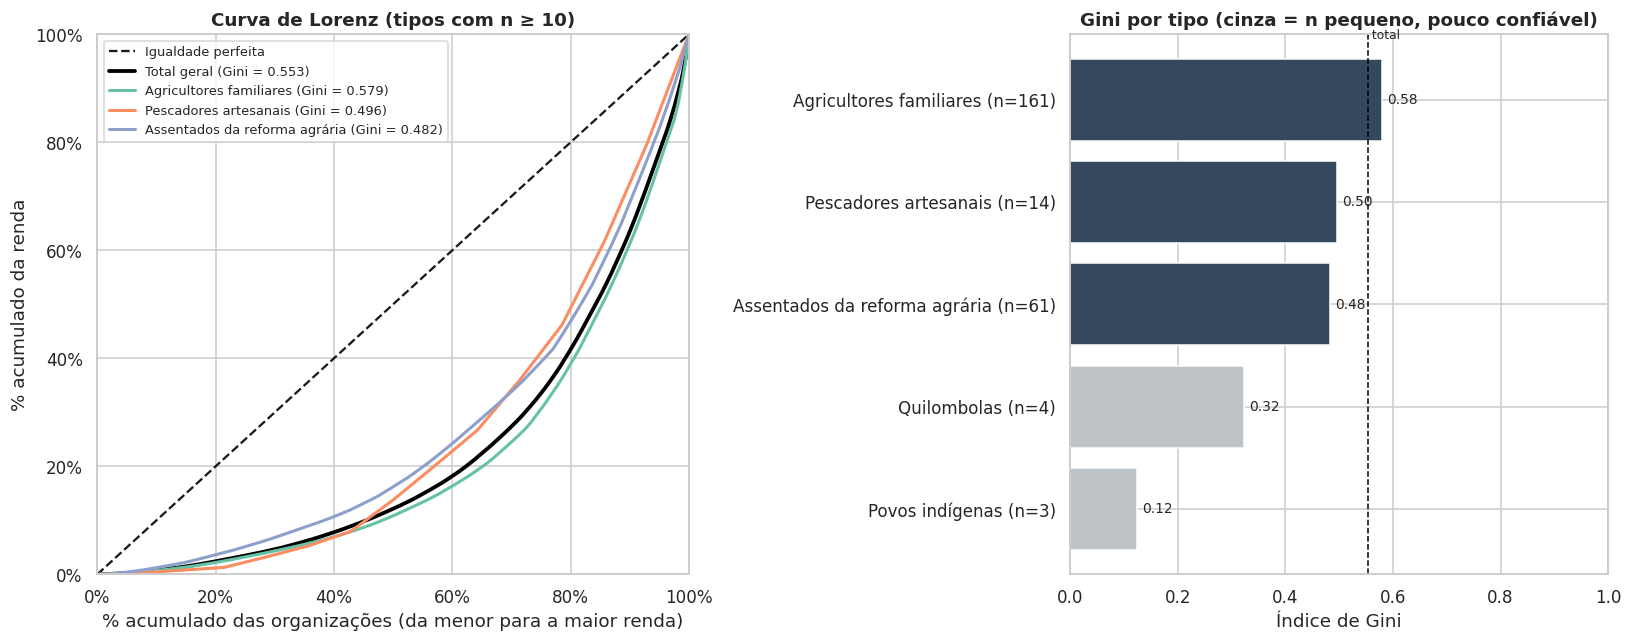

In [ ]:
grupos = conc[(conc['TIPO'] != 'TOTAL GERAL') & (conc['N_ORGS'] >= MIN_N)]['TIPO'].tolist()
cores = dict(zip(grupos, sns.color_palette('Set2', len(grupos))))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1.1, 1]})

a1.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Igualdade perfeita')
x, yl = lorenz(renda_org['RENDA'])
a1.plot(x, yl, color='black', lw=2.5, label=f"Total geral (Gini = {conc.loc[0, 'GINI']:.3f})")
for t in grupos:
    x, yl = lorenz(renda_org.loc[renda_org['TIPO'] == t, 'RENDA'])
    a1.plot(x, yl, color=cores[t], lw=2, label=f"{t} (Gini = {conc.loc[conc['TIPO'] == t, 'GINI'].iloc[0]:.3f})")
a1.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
a1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
a1.set(xlim=(0, 1), ylim=(0, 1), xlabel='% acumulado das organizações (da menor para a maior renda)',
       ylabel='% acumulado da renda', title=f'Curva de Lorenz (tipos com n ≥ {MIN_N})')
a1.legend(loc='upper left', fontsize=8.5)

d = conc[(conc['TIPO'] != 'TOTAL GERAL') & conc['GINI'].notna()].sort_values('GINI')
barras = a2.barh([f'{t} (n={n})' for t, n in zip(d['TIPO'], d['N_ORGS'])], d['GINI'],
                 color=['#34495e' if n >= MIN_N else '#bdc3c7' for n in d['N_ORGS']])
for rect in barras:
    a2.text(rect.get_width() + 0.01, rect.get_y() + rect.get_height() / 2, f'{rect.get_width():.2f}', va='center', fontsize=9)
a2.axvline(conc.loc[0, 'GINI'], color='black', ls='--', lw=1)
a2.text(conc.loc[0, 'GINI'], len(d) - 0.4, ' total', fontsize=8)
a2.set(xlim=(0, 1), xlabel='Índice de Gini', title='Gini por tipo (cinza = n pequeno, pouco confiável)')
plt.tight_layout()
plt.show()

**Análise do gráfico.** *O que mostra:* o Gini geral é 0,553 (0,564 se a unidade for o CNPJ). A curva dos agricultores familiares (0,579) fica abaixo da curva geral, ou seja, é o grupo **mais desigual**; assentados (0,482) e pescadores (0,496) ficam acima, sendo mais igualitários. Na base inteira, a metade de menor renda das organizações fica com apenas 11,7% do valor.

*Leitura crítica:* (1) um Gini próximo de 0,55 indica desigualdade alta; como referência, a renda domiciliar brasileira tem Gini em torno de 0,5 (confira o dado mais recente do IBGE). Isto é, a distribuição entre organizações é tão concentrada quanto a da renda das famílias do país. (2) Os Ginis baixos de quilombolas (0,32; n = 4) e indígenas (0,12; n = 3) **não indicam equidade**: refletem poucas organizações com contratos pequenos e parecidos. Por isso ficam fora das curvas de Lorenz e aparecem em cinza.

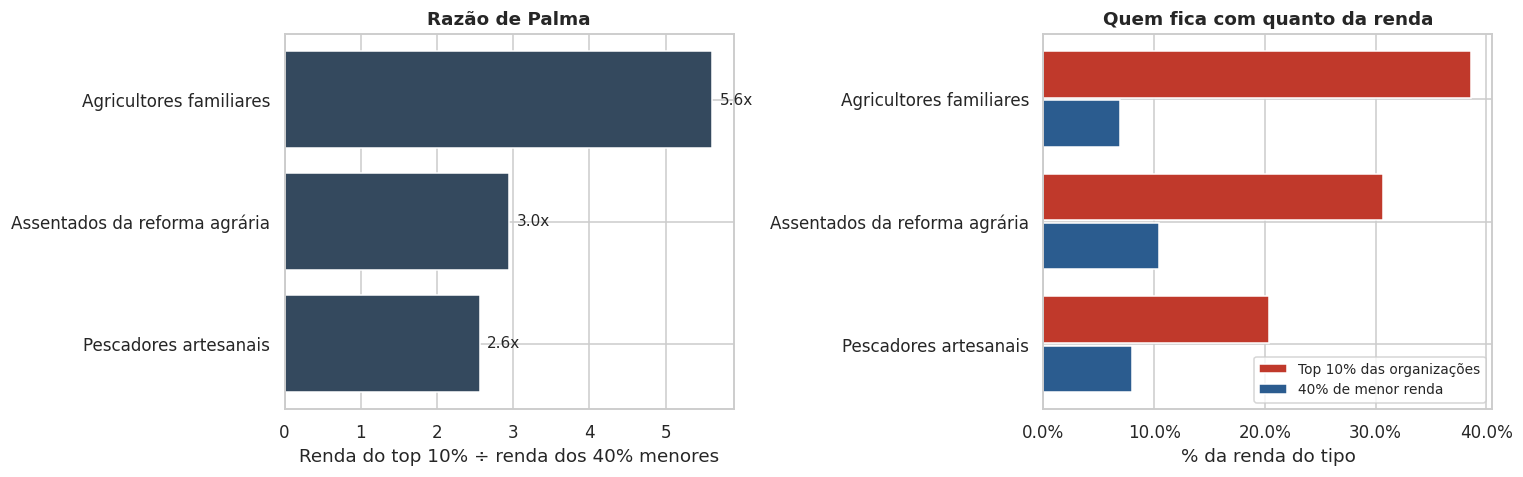

In [ ]:
# Palma e participação do topo/base (apenas grupos com n suficiente)
d = conc[(conc['TIPO'] != 'TOTAL GERAL') & (conc['N_ORGS'] >= MIN_N)].sort_values('PALMA')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))

b = a1.barh(d['TIPO'], d['PALMA'], color='#34495e')
for rect in b:
    a1.text(rect.get_width() + 0.1, rect.get_y() + rect.get_height() / 2, f'{rect.get_width():.1f}x', va='center', fontsize=10)
a1.set(xlabel='Renda do top 10% ÷ renda dos 40% menores', title='Razão de Palma')

y = np.arange(len(d))
a2.barh(y + 0.2, d['TOP10_%'], height=0.38, color='#c0392b', label='Top 10% das organizações')
a2.barh(y - 0.2, d['BASE40_%'], height=0.38, color='#2b5c8f', label='40% de menor renda')
a2.set_yticks(y)
a2.set_yticklabels(d['TIPO'])
a2.xaxis.set_major_formatter(mtick.PercentFormatter())
a2.set(xlabel='% da renda do tipo', title='Quem fica com quanto da renda')
a2.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

**Análise do gráfico.** *O que mostra:* a razão de Palma é 5,6x nos agricultores familiares, 2,9x nos assentados e 2,6x nos pescadores (4,6x na base inteira). Nos agricultores, o top 10% das organizações (16 delas) fica com 38,6% da renda do tipo e os 40% menores (64 organizações) com 6,9%.

*Leitura crítica:* a Palma compara fatias de tamanhos diferentes (10% vs. 40% das organizações). Em termos por organização, uma organização do topo dos agricultores familiares recebe em média **cerca de 22 vezes** o de uma organização da base (5,6 × 4); na base inteira, cerca de 18 vezes. A diferença entre tipos é grande e o grupo dominante é também o mais desigual, de modo que políticas pensadas "para a agricultura familiar" em média atingem uma realidade muito heterogênea.

### 5.1 Concentração na base inteira

As 10 maiores organizações concentram 20.6% da renda total.


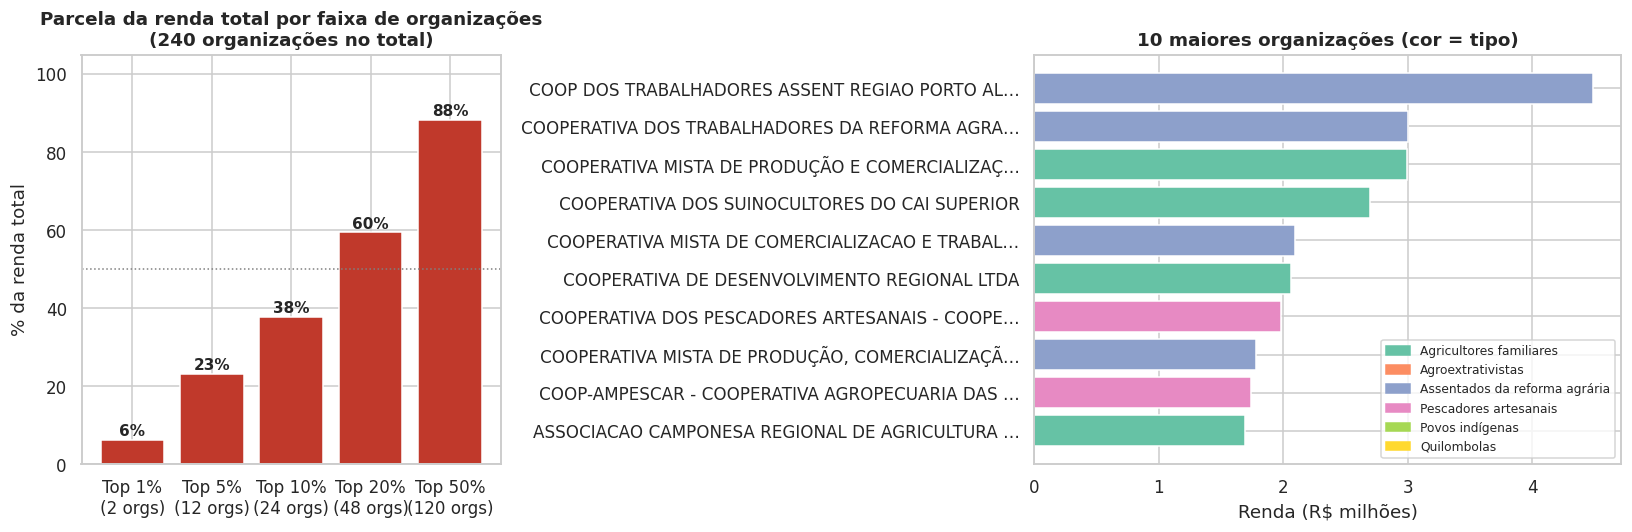

In [ ]:
# Concentração na base inteira: quanto da renda fica com o topo?
org_total = df.groupby('ORG_ID').agg(NOME=('NOME', 'first'), TIPO=('TIPO', lambda s: s.mode().iloc[0]), RENDA=('VALOR', 'sum'))
valores = org_total['RENDA'].values
fracs = [0.01, 0.05, 0.10, 0.20, 0.50]
partes = [parcela_topo(valores, f) * 100 for f in fracs]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 1.4]})
b = a1.bar([f'Top {int(f * 100)}%\n({max(1, round(len(valores) * f))} orgs)' for f in fracs], partes, color='#c0392b')
for rect, p in zip(b, partes):
    a1.text(rect.get_x() + rect.get_width() / 2, p + 1, f'{p:.0f}%', ha='center', fontsize=10, fontweight='bold')
a1.axhline(50, color='gray', ls=':', lw=1)
a1.set(ylim=(0, 105), ylabel='% da renda total', title=f'Parcela da renda total por faixa de organizações\n({len(valores)} organizações no total)')

top10 = org_total.sort_values('RENDA', ascending=False).head(10).iloc[::-1]
paleta = dict(zip(sorted(df['TIPO'].unique()), sns.color_palette('Set2', df['TIPO'].nunique())))
a2.barh([n[:45] + ('…' if len(n) > 45 else '') for n in top10['NOME']], top10['RENDA'] / 1e6,
        color=[paleta[t] for t in top10['TIPO']])
a2.set(xlabel='Renda (R$ milhões)', title='10 maiores organizações (cor = tipo)')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in paleta.values()]
a2.legend(handles, paleta.keys(), fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

print(f'As 10 maiores organizações concentram {top10["RENDA"].sum() / valores.sum():.1%} da renda total.')

**Análise do gráfico.** *O que mostra:* o top 1% das organizações (2 a 3) concentra 6,3% da renda; o top 5%, 23,2%; o top 10% (24), 37,8%; o top 20%, 59,5%; e a metade de baixo, só 11,7%. A maior organização sozinha tem 3,8% do total (R\$ 4,5 mi) e as 10 maiores somam 20,6%.

*Leitura crítica:* (1) **não há monopólio**: nenhuma organização domina; a concentração é de um "andar de cima" de algumas dezenas de organizações. (2) Esse andar de cima tem perfil claro: **9 das 10 maiores são cooperativas**, 6 do Sul (em especial do Rio Grande do Sul), 3 do Sudeste e 1 do Centro-Oeste. **Nenhuma é do Norte ou do Nordeste**, embora o Nordeste tenha 38,8% das organizações. (3) Por tipo, são 4 assentados, 4 agricultores familiares e 2 pescadores. Isso conecta a concentração individual à assimetria regional e à capacidade de escala, e não ao tipo declarado.

## 6. Perfil das organizações

### 6.1 Participação por tipo e variedade de produtos
### 6.2 Povos e comunidades tradicionais

Organizações quilombolas + indígenas: 7 (2.9% das organizações) com R$ 1.450.992,39 (1.22% da renda).
Renda média por organização: R$ 207.284,63 (quilombolas + indígenas) vs. R$ 488.555,23 (todas).
Atenção: são poucas organizações (n < 10); os valores descrevem o caso, mas não permitem inferência estatística.
Fornecedores quilombolas em organizações de OUTRO tipo: 56% | indígenas em organizações de OUTRO tipo: 20%
Quilombolas + indígenas = 196 de 8.156 fornecedores (2.4%).


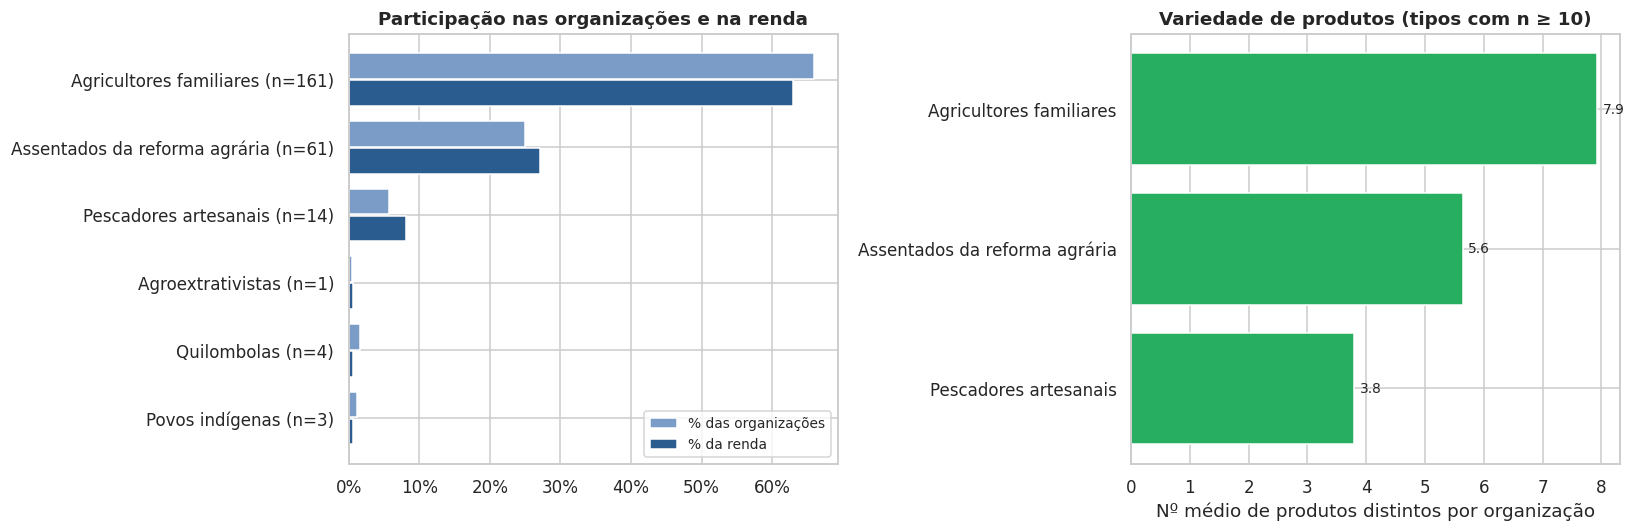

,QUILOMBOLAS,INDIGENAS,PESCADORES,AGROEXTRATIVISTAS,PCT
TIPO_DECL,,,,,
Agricultores familiares,84,5,14,72,175
Agroextrativistas,0,0,0,161,161
Assentados da reforma agrária,4,3,30,6,43
Pescadores artesanais,0,0,585,11,596
Povos indígenas,0,32,0,12,44
Quilombolas,68,0,13,0,81
TOTAL,156,40,642,262,1100


In [ ]:
# 6.1 Participação de cada tipo (% das organizações x % da renda) e variedade de produtos
d = resumo.sort_values('PCT_RENDA')
y = np.arange(len(d))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5))

a1.barh(y + 0.2, d['PCT_ORGS'], height=0.38, color='#7a9cc6', label='% das organizações')
a1.barh(y - 0.2, d['PCT_RENDA'], height=0.38, color='#2b5c8f', label='% da renda')
a1.set_yticks(y)
a1.set_yticklabels([f'{t} (n={n})' for t, n in zip(d['TIPO'], d['N_ORGS'])])
a1.xaxis.set_major_formatter(mtick.PercentFormatter())
a1.set_title('Participação nas organizações e na renda')
a1.legend(fontsize=9, loc='lower right')

dv = resumo[resumo['N_ORGS'] >= MIN_N].sort_values('PRODUTOS_POR_ORG')
b = a2.barh(dv['TIPO'], dv['PRODUTOS_POR_ORG'], color='#27ae60')
for rect in b:
    a2.text(rect.get_width() + 0.1, rect.get_y() + rect.get_height() / 2, f'{rect.get_width():.1f}', va='center', fontsize=9)
a2.set(xlabel='Nº médio de produtos distintos por organização', title=f'Variedade de produtos (tipos com n ≥ {MIN_N})')
plt.tight_layout()
plt.show()

# 6.2 Povos e comunidades tradicionais: organizações (CNPJ) e fornecedores individuais
trad = resumo[resumo['TIPO'].isin(['Quilombolas', 'Povos indígenas'])]
print(f"Organizações quilombolas + indígenas: {trad['N_ORGS'].sum()} ({trad['PCT_ORGS'].sum():.1f}% das organizações) "
      f"com {brl(trad['RENDA_TOTAL'].sum())} ({trad['PCT_RENDA'].sum():.2f}% da renda).")
print(f"Renda média por organização: {brl(trad['RENDA_TOTAL'].sum() / trad['N_ORGS'].sum())} (quilombolas + indígenas) "
      f"vs. {brl(renda_org['RENDA'].mean())} (todas).")
print('Atenção: são poucas organizações (n < 10); os valores descrevem o caso, mas não permitem inferência estatística.')


# 6.2.1 Onde estão os fornecedores quilombolas, indígenas e "PCT"? (por tipo declarado da organização)
contr['TIPO_DECL'] = contr['ORG_ID'].map(contr.drop_duplicates('ORG_ID').set_index('ORG_ID')['Tipo de Organização Declarada'].map(padronizar_tipo))
onde = contr.groupby('TIPO_DECL')[['QUILOMBOLAS', 'INDIGENAS', 'PESCADORES', 'AGROEXTRATIVISTAS', 'PCT']].sum().astype(int)
onde.loc['TOTAL'] = onde.sum()
display(onde)
q_fora = 1 - onde.loc['Quilombolas', 'QUILOMBOLAS'] / onde.loc['TOTAL', 'QUILOMBOLAS']
i_fora = 1 - onde.loc['Povos indígenas', 'INDIGENAS'] / onde.loc['TOTAL', 'INDIGENAS']
print(f"Fornecedores quilombolas em organizações de OUTRO tipo: {q_fora:.0%} | indígenas em organizações de OUTRO tipo: {i_fora:.0%}")
print(f"Quilombolas + indígenas = {onde.loc['TOTAL', 'QUILOMBOLAS'] + onde.loc['TOTAL', 'INDIGENAS']} de {contr['FORNECEDORES'].sum():,.0f} fornecedores "
      f"({(onde.loc['TOTAL', 'QUILOMBOLAS'] + onde.loc['TOTAL', 'INDIGENAS']) / contr['FORNECEDORES'].sum():.1%}).".replace(',', '.'))

**Análise dos gráficos.** *Participação:* agricultores familiares têm 66,0% das organizações e 62,9% da renda (levemente sub-representados em renda); pescadores têm 5,7% das organizações e 8,1% da renda; quilombolas (1,6% vs. 0,6%) e indígenas (1,2% vs. 0,6%) recebem **de 40% a 50%** do que sua presença em número de organizações sugeriria.

*Variedade de produtos:* agricultores familiares fornecem 7,9 produtos distintos por organização, contra 5,6 dos assentados e 3,8 dos pescadores. Teste: a diferença é de +68% (p = 0,001) e **permanece em +61% (p = 0,002) ao controlar pela renda da organização**, então não é só efeito de porte. A correlação entre renda e variedade é, aliás, levemente negativa (ρ = −0,14): contratos grandes costumam ter poucas linhas (várias das maiores organizações têm só 1 a 3 itens, com média acima de R\$ 1 milhão cada).

*Ressalvas:* "produtos distintos" depende de como cada proposta lista os itens, e o tipo condiciona a produção (pesca tem pouca variedade por natureza). A comparação mais informativa é agricultores (7,9) vs. assentados (5,6). O agroextrativista (71 produtos) é uma única organização.

*Quilombolas e indígenas:* a tabela mostra que 80% dos fornecedores indígenas (32 de 40) estão em organizações indígenas, e 56% dos quilombolas (88 de 156) em organizações de outro tipo, principalmente agricultores familiares. Somados, são 2,4% dos fornecedores. Os "PCT" (13,5%) são em sua maioria pescadores e agroextrativistas.

### 6.3 Mulheres entre os fornecedores

Coluna 'ORG DE MULHERES' (aba PRODUTOS): 0 registros preenchidos de 1995 -> não serve para medir o recorte. Usa-se a aba CONTRATAÇÕES (nº de mulheres entre os fornecedores).

Mulheres: 5.421 de 8.156 fornecedores previstos (66.5%).
Spearman % de mulheres × renda da organização: ρ = -0.27 (p = 0.000)
Spearman % de mulheres × renda por fornecedor: ρ = -0.21 (p = 0.001)
Mann-Whitney (organizações predominantemente femininas recebem MENOS): p = 0.000


,PRED_MULH,ORGS,RENDA_TOTAL,RENDA_MEDIANA,RENDA_POR_FORNEC,FORNEC,PCT_RENDA,PCT_ORGS
0,Demais (<75% de mulheres),150,"R$ 92.228.875,50","R$ 349.599,40","R$ 14.486,09",6112,77.4%,62.5%
1,Predominantemente femininas (≥75%),90,"R$ 26.978.600,64","R$ 154.977,50","R$ 12.307,12",2044,22.6%,37.5%


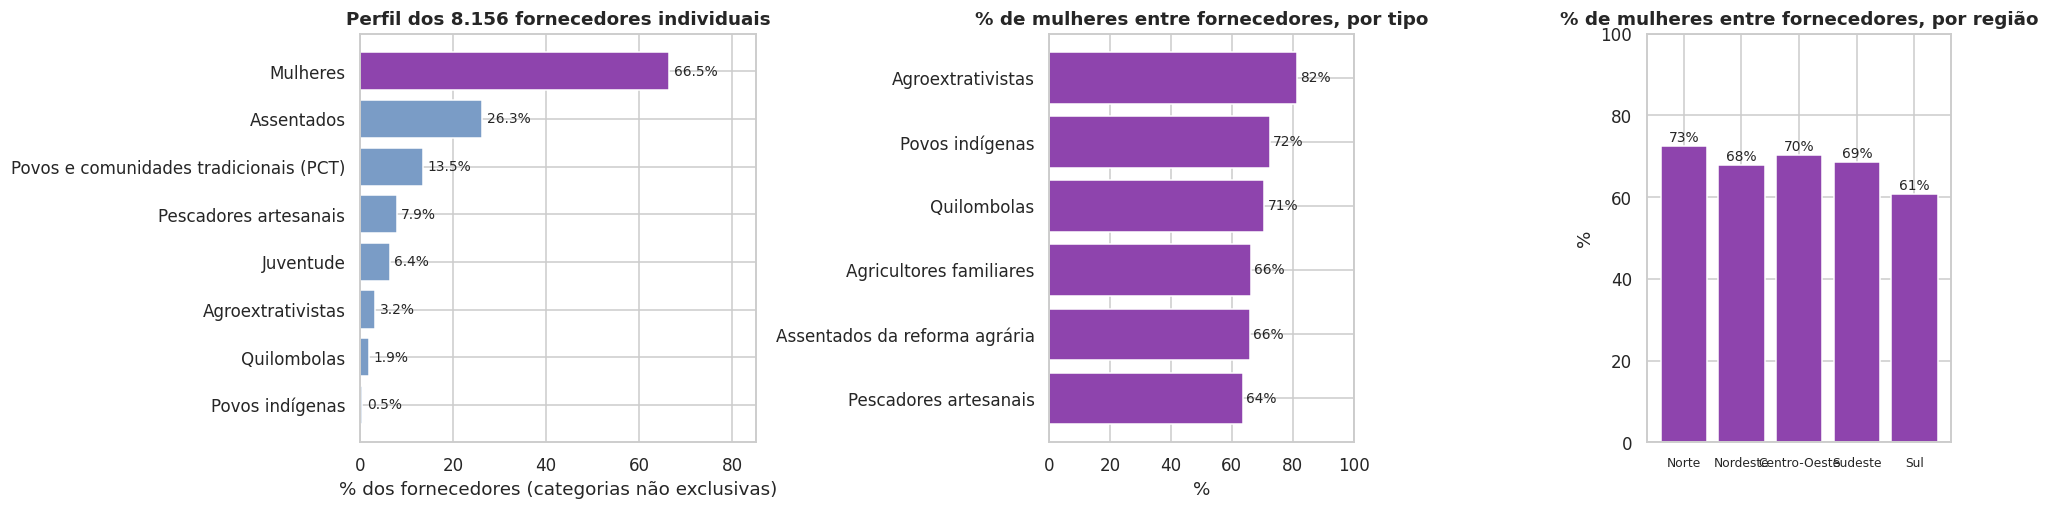

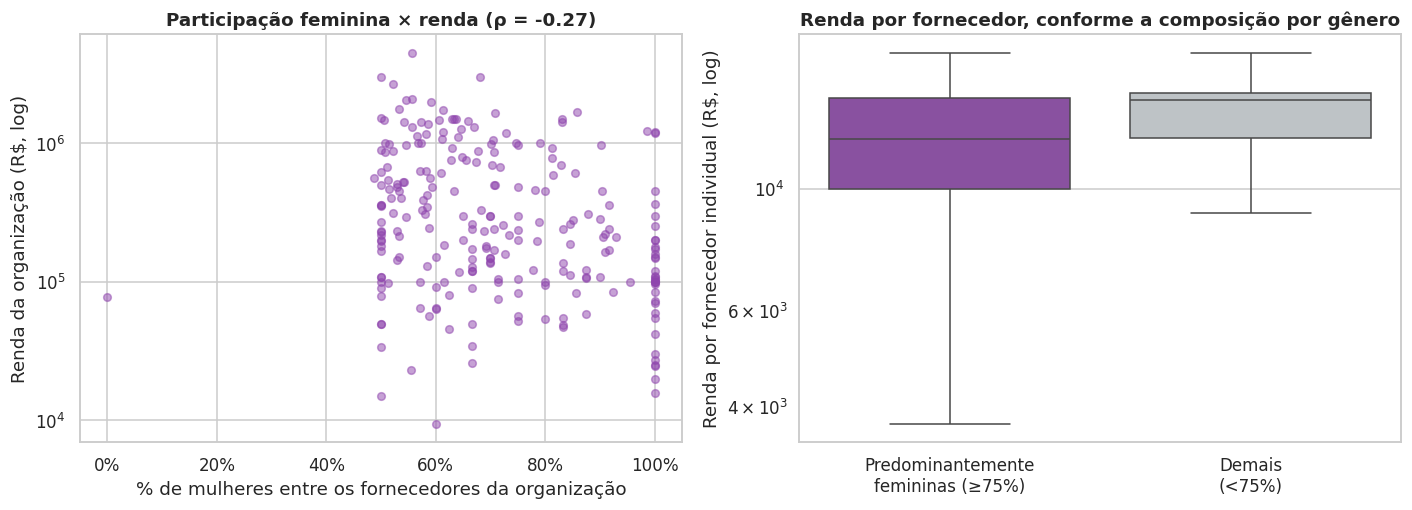

In [ ]:
print(f"Coluna 'ORG DE MULHERES' (aba PRODUTOS): {df['ORG DE MULHERES'].notna().sum()} registros preenchidos de {len(df)} "
      "-> não serve para medir o recorte. Usa-se a aba CONTRATAÇÕES (nº de mulheres entre os fornecedores).\n")

# 6.3.1 Perfil dos fornecedores individuais (categorias não são exclusivas: uma pessoa pode ser mulher e assentada)
tot_forn = contr['FORNECEDORES'].sum()
cats = {'Mulheres': 'MULHERES', 'Assentados': 'ASSENTADOS', 'Pescadores artesanais': 'PESCADORES',
        'Povos e comunidades tradicionais (PCT)': 'PCT', 'Juventude': 'JUVENTUDE',
        'Agroextrativistas': 'AGROEXTRATIVISTAS', 'Quilombolas': 'QUILOMBOLAS', 'Povos indígenas': 'INDIGENAS'}
perfil_forn = pd.Series({k: contr[v].sum() / tot_forn * 100 for k, v in cats.items()}).sort_values()

# 6.3.2 Participação feminina por organização
org_f = contr.groupby('ORG_ID').agg(FORNEC=('FORNECEDORES', 'sum'), MULH=('MULHERES', 'sum'), VALOR=('VALOR_PREVISTO', 'sum'),
                                    REGIAO=('REGIAO', 'first')).reset_index()
org_f = org_f[org_f['FORNEC'] > 0].copy()
org_f['PCT_MULH'] = (org_f['MULH'] / org_f['FORNEC']).clip(upper=1)
LIMIAR_MULH = 0.75   # quase todas as organizações têm ≥50% de mulheres; por isso o corte é 75%
org_f['PRED_MULH'] = org_f['PCT_MULH'] >= LIMIAR_MULH
org_f['VALOR_POR_FORNEC'] = org_f['VALOR'] / org_f['FORNEC']

grupo_f = org_f.groupby('PRED_MULH').agg(ORGS=('ORG_ID', 'size'), RENDA_TOTAL=('VALOR', 'sum'), RENDA_MEDIANA=('VALOR', 'median'),
                                            RENDA_POR_FORNEC=('VALOR_POR_FORNEC', 'median'), FORNEC=('FORNEC', 'sum')).reset_index()
grupo_f['PRED_MULH'] = grupo_f['PRED_MULH'].map({True: 'Predominantemente femininas (≥75%)', False: 'Demais (<75% de mulheres)'})
grupo_f['PCT_RENDA'] = grupo_f['RENDA_TOTAL'] / grupo_f['RENDA_TOTAL'].sum() * 100
grupo_f['PCT_ORGS'] = grupo_f['ORGS'] / grupo_f['ORGS'].sum() * 100

print(f'Mulheres: {contr["MULHERES"].sum():,.0f} de {tot_forn:,.0f} fornecedores previstos ({contr["MULHERES"].sum() / tot_forn:.1%}).'.replace(',', '.'))
mostrar(grupo_f, brl_cols=['RENDA_TOTAL', 'RENDA_MEDIANA', 'RENDA_POR_FORNEC'], pct_cols=['PCT_RENDA', 'PCT_ORGS'])

# Mulheres por tipo e por região
tipo_declarado = contr.drop_duplicates('ORG_ID').set_index('ORG_ID')['Tipo de Organização Declarada'].map(padronizar_tipo)
contr['TIPO'] = contr['ORG_ID'].map(tipo_declarado)
mt = contr.groupby('TIPO')[['MULHERES', 'FORNECEDORES']].sum()
mt = (mt['MULHERES'] / mt['FORNECEDORES'] * 100).sort_values()
mr = contr.groupby('REGIAO')[['MULHERES', 'FORNECEDORES']].sum()
mr = (mr['MULHERES'] / mr['FORNECEDORES'] * 100).reindex(['Norte', 'Nordeste', 'Centro-Oeste', 'Sudeste', 'Sul'])

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={'width_ratios': [1.3, 1, 1]})
b = ax[0].barh(perfil_forn.index, perfil_forn.values, color=['#8e44ad' if i == 'Mulheres' else '#7a9cc6' for i in perfil_forn.index])
for rect in b:
    ax[0].text(rect.get_width() + 1, rect.get_y() + rect.get_height() / 2, f'{rect.get_width():.1f}%', va='center', fontsize=9)
ax[0].set(xlim=(0, 85), title=f'Perfil dos {tot_forn:,.0f} fornecedores individuais'.replace(',', '.'), xlabel='% dos fornecedores (categorias não exclusivas)')
b = ax[1].barh(mt.index, mt.values, color='#8e44ad')
for rect in b:
    ax[1].text(rect.get_width() + 1, rect.get_y() + rect.get_height() / 2, f'{rect.get_width():.0f}%', va='center', fontsize=9)
ax[1].set(xlim=(0, 100), title='% de mulheres entre fornecedores, por tipo', xlabel='%')
b = ax[2].bar(mr.index, mr.values, color='#8e44ad')
for rect in b:
    ax[2].text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 1, f'{rect.get_height():.0f}%', ha='center', fontsize=9)
ax[2].set(ylim=(0, 100), title='% de mulheres entre fornecedores, por região', ylabel='%')
ax[2].tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.show()

# Organizações com mais mulheres recebem menos? (renda por organização e por fornecedor)
rho_f, p_rho_f = stats.spearmanr(org_f['PCT_MULH'], org_f['VALOR'])
rho_p, p_rho_p = stats.spearmanr(org_f['PCT_MULH'], org_f['VALOR_POR_FORNEC'])
U_f, p_f = stats.mannwhitneyu(org_f.loc[org_f['PRED_MULH'], 'VALOR'], org_f.loc[~org_f['PRED_MULH'], 'VALOR'], alternative='less')
print(f'Spearman % de mulheres × renda da organização: ρ = {rho_f:.2f} (p = {p_rho_f:.3f})')
print(f'Spearman % de mulheres × renda por fornecedor: ρ = {rho_p:.2f} (p = {p_rho_p:.3f})')
print(f'Mann-Whitney (organizações predominantemente femininas recebem MENOS): p = {p_f:.3f}')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
a1.scatter(org_f['PCT_MULH'] * 100, org_f['VALOR'], alpha=.5, color='#8e44ad', s=25)
a1.set(yscale='log', xlabel='% de mulheres entre os fornecedores da organização', ylabel='Renda da organização (R$, log)',
       title=f'Participação feminina × renda (ρ = {rho_f:.2f})')
a1.xaxis.set_major_formatter(mtick.PercentFormatter())
sns.boxplot(data=org_f.assign(G=org_f['PRED_MULH'].map({True: 'Predominantemente\nfemininas (≥75%)', False: 'Demais\n(<75%)'})), x='G', y='VALOR_POR_FORNEC',
            palette=['#8e44ad', '#bdc3c7'], showfliers=False, ax=a2)
a2.set(yscale='log', xlabel='', ylabel='Renda por fornecedor individual (R$, log)', title='Renda por fornecedor, conforme a composição por gênero')
plt.tight_layout()
plt.show()

**Análise dos gráficos.** *Perfil e gênero:* 66,5% dos fornecedores previstos são mulheres, de 63,6% (pescadores) a 81,5% (agroextrativistas) conforme o tipo, e de 60,8% (Sul) a 72,5% (Norte) conforme a região. Juventude é só 6,4% dos fornecedores, assentados 26,3%, quilombolas 1,9% e indígenas 0,5%.

*Participação feminina e renda:* quanto maior a proporção de mulheres, menor a renda da organização (ρ = −0,27). As 90 organizações com ≥ 75% de mulheres têm mediana de R\$ 155 mil, contra R\$ 350 mil nas demais (−56%).

*Leitura crítica:* (1) a diferença vem **sobretudo do porte**: essas organizações têm 22,7 fornecedores em média, contra 40,7 nas demais (−44%). Por fornecedor, a diferença é bem menor (R\$ 12,3 mil vs. R\$ 14,5 mil, −15%) e **desaparece na regressão** com controle de porte (seção 7.7). (2) A região com maior escala de organizações, o Sul, é também a de menor proporção de mulheres (60,8%), o que combina com mulheres concentradas em organizações menores. (3) O dado de **juventude** (6,4%) é o menor entre as categorias, depois dos povos tradicionais, e merece atenção própria, pois não foi analisado além do perfil. (4) Os números são de fornecedores *previstos* nas propostas, não de beneficiários efetivos dos pagamentos.

## 7. Análise territorial

Esta seção testa a hipótese de pesquisa: *a distribuição do orçamento reproduz assimetrias regionais, favorecendo Sul/Sudeste em detrimento de Norte/Nordeste?* Cada subseção responde a uma das subperguntas operacionais:

| Subpergunta | Onde |
|---|---|
| Diferencial de aporte financeiro (média/mediana por organização e significância estatística) | 7.2 e 7.3 |
| Capacidade institucional vs. cobertura (nº de organizações vs. renda; cooperativismo) | 7.2 e 7.5 |
| Alinhamento com a vulnerabilidade (renda per capita × INSAN) | 7.2 e 7.6 |

### 7.1 Indicadores por região

In [ ]:
# Referências territoriais ------------------------------------------------------------
# População por região – Censo IBGE 2022 (valores aproximados; confira em sidra.ibge.gov.br, tabela 4709)
POPULACAO = {'Norte': 17_354_884, 'Nordeste': 54_644_582, 'Centro-Oeste': 16_289_538,
             'Sudeste': 84_847_187, 'Sul': 29_937_706}

# Insegurança alimentar (INSAN) por região, em % dos domicílios (IBGE/PNAD ou VIGISAN).
# Preencha para ativar o teste de alinhamento com a vulnerabilidade (seção 7.5). Ex.: {'Norte': 0.0, ...}
INSAN_REGIAO = {}
# ---------------------------------------------------------------------------------------

ORDEM_REG = ['Norte', 'Nordeste', 'Centro-Oeste', 'Sudeste', 'Sul']
org_reg = df.groupby(['REGIAO', 'ORG_ID']).agg(RENDA=('VALOR', 'sum'), COOPERATIVA=('COOPERATIVA', 'max'),
                                               PROPOSTAS=('TPAF', 'nunique')).reset_index()

reg = (org_reg.groupby('REGIAO')
              .agg(RENDA_TOTAL=('RENDA', 'sum'), N_ORGS=('ORG_ID', 'nunique'),
                   MEDIA=('RENDA', 'mean'), MEDIANA=('RENDA', 'median'),
                   PCT_COOP=('COOPERATIVA', lambda s: s.mean() * 100),
                   PROPOSTAS=('PROPOSTAS', 'sum'))
              .reindex(ORDEM_REG))
reg['PCT_RENDA'] = reg['RENDA_TOTAL'] / reg['RENDA_TOTAL'].sum() * 100
reg['PCT_ORGS'] = reg['N_ORGS'] / reg['N_ORGS'].sum() * 100
reg['POPULACAO'] = pd.Series(POPULACAO)
reg['RENDA_PER_CAPITA'] = reg['RENDA_TOTAL'] / reg['POPULACAO']
reg['ORGS_POR_MILHAO_HAB'] = reg['N_ORGS'] / (reg['POPULACAO'] / 1e6)
reg['TICKET_PROPOSTA'] = reg['RENDA_TOTAL'] / reg['PROPOSTAS'].replace(0, np.nan)

# Demanda e fornecedores individuais (aba CONTRATAÇÕES, por região da proposta)
cr = contr.groupby('REGIAO').agg(BENEFICIARIOS=('BENEFICIARIOS', 'sum'), FORNECEDORES=('FORNECEDORES', 'sum')).reindex(ORDEM_REG)
reg['BENEFICIARIOS'] = cr['BENEFICIARIOS']
reg['FORNECEDORES'] = cr['FORNECEDORES']
reg['RENDA_POR_BENEFICIARIO'] = reg['RENDA_TOTAL'] / reg['BENEFICIARIOS']
reg['RENDA_POR_FORNECEDOR'] = reg['RENDA_TOTAL'] / reg['FORNECEDORES']
reg['FORNEC_POR_ORG'] = (reg['FORNECEDORES'] / reg['N_ORGS']).round(1)

mostrar(reg.reset_index(), brl_cols=['RENDA_TOTAL', 'MEDIA', 'MEDIANA', 'RENDA_PER_CAPITA', 'TICKET_PROPOSTA', 'RENDA_POR_BENEFICIARIO', 'RENDA_POR_FORNECEDOR'],
        pct_cols=['PCT_RENDA', 'PCT_ORGS', 'PCT_COOP'], dec_cols=['ORGS_POR_MILHAO_HAB'])

,REGIAO,RENDA_TOTAL,N_ORGS,MEDIA,MEDIANA,PCT_COOP,PROPOSTAS,PCT_RENDA,PCT_ORGS,POPULACAO,RENDA_PER_CAPITA,ORGS_POR_MILHAO_HAB,TICKET_PROPOSTA,BENEFICIARIOS,FORNECEDORES,RENDA_POR_BENEFICIARIO,RENDA_POR_FORNECEDOR,FORNEC_POR_ORG
0,Norte,"R$ 7.365.284,52",32,"R$ 230.165,14","R$ 103.352,08",43.8%,36,6.2%,13.3%,17354884,"R$ 0,42",1.844,"R$ 204.591,24",69217.0,710,"R$ 106,41","R$ 10.373,64",22.2
1,Nordeste,"R$ 37.305.023,56",93,"R$ 401.129,29","R$ 214.998,32",41.9%,97,31.3%,38.8%,54644582,"R$ 0,68",1.702,"R$ 384.587,87",547131.0,2731,"R$ 68,18","R$ 13.659,84",29.4
2,Centro-Oeste,"R$ 6.793.042,38",26,"R$ 261.270,86","R$ 90.043,79",50.0%,30,5.7%,10.8%,16289538,"R$ 0,42",1.596,"R$ 226.434,75",41007.0,489,"R$ 165,66","R$ 13.891,70",18.8
3,Sudeste,"R$ 28.934.201,97",41,"R$ 705.712,24","R$ 525.000,00",56.1%,50,24.3%,17.1%,84847187,"R$ 0,34",0.483,"R$ 578.684,04",407369.0,1733,"R$ 71,03","R$ 16.696,02",42.3
4,Sul,"R$ 38.809.923,71",48,"R$ 808.540,08","R$ 459.277,59",81.2%,67,32.6%,20.0%,29937706,"R$ 1,30",1.603,"R$ 579.252,59",400134.0,2493,"R$ 96,99","R$ 15.567,56",51.9


### 7.2 Painel regional

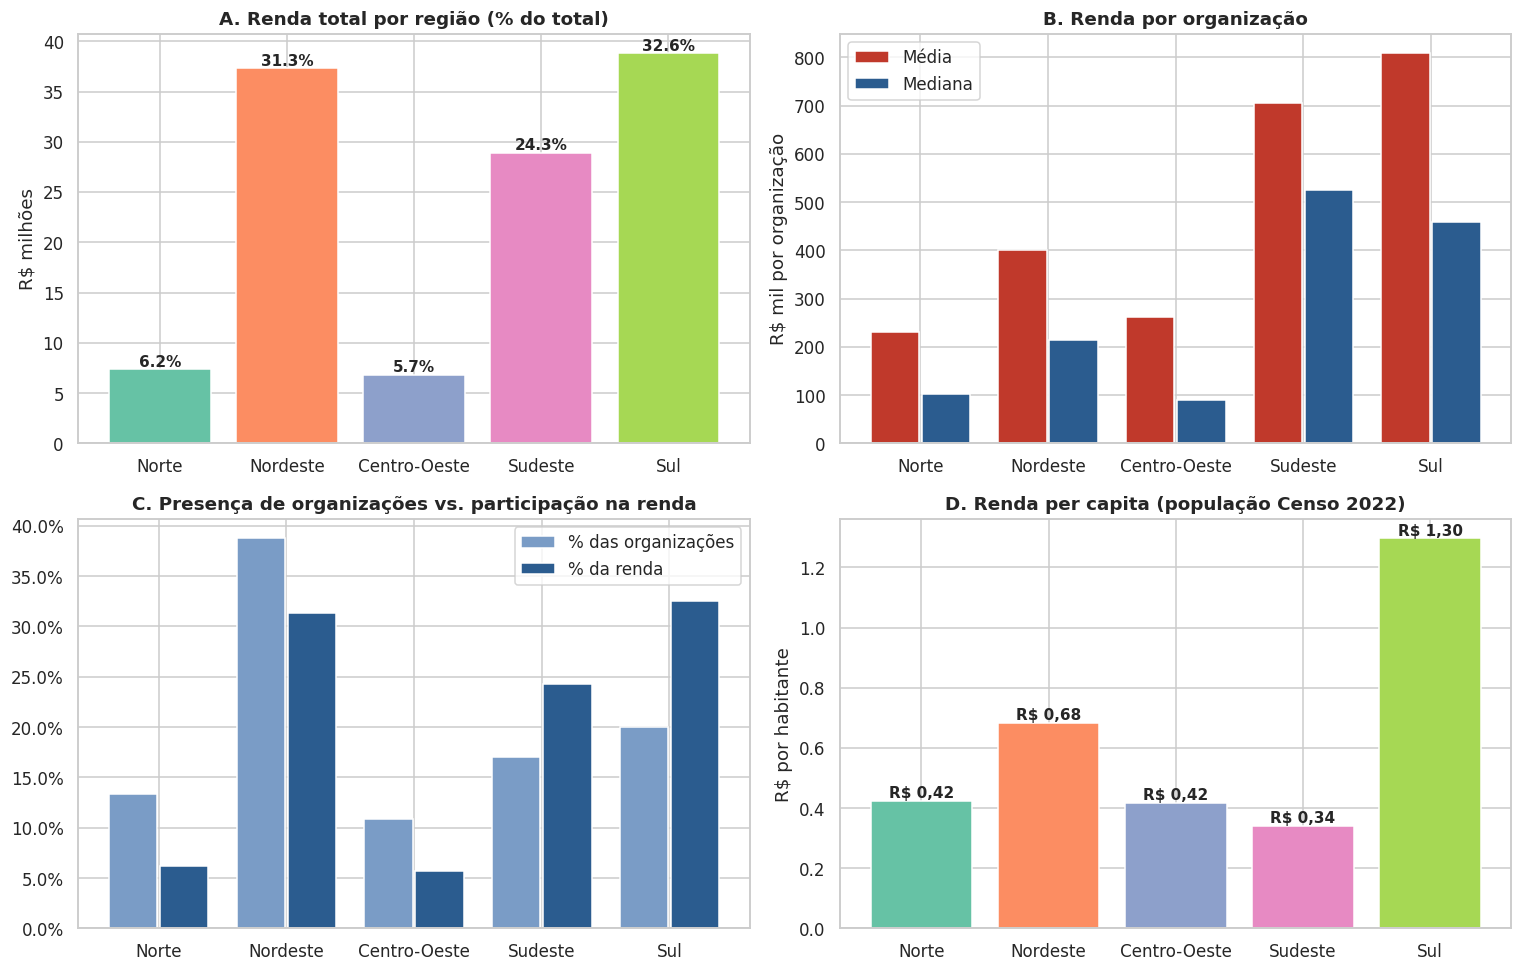

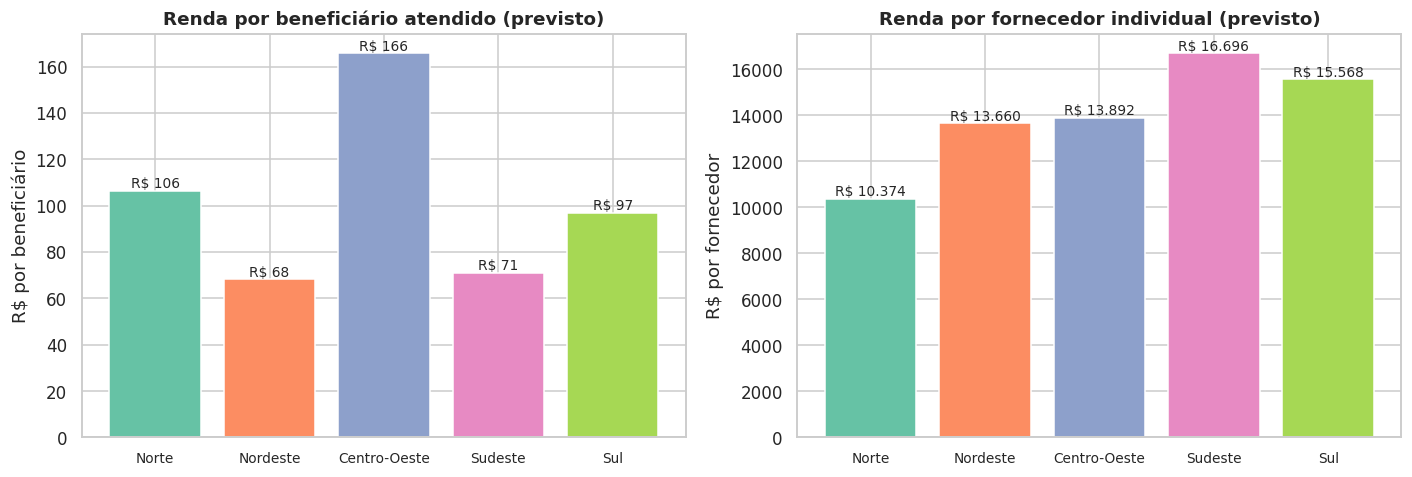

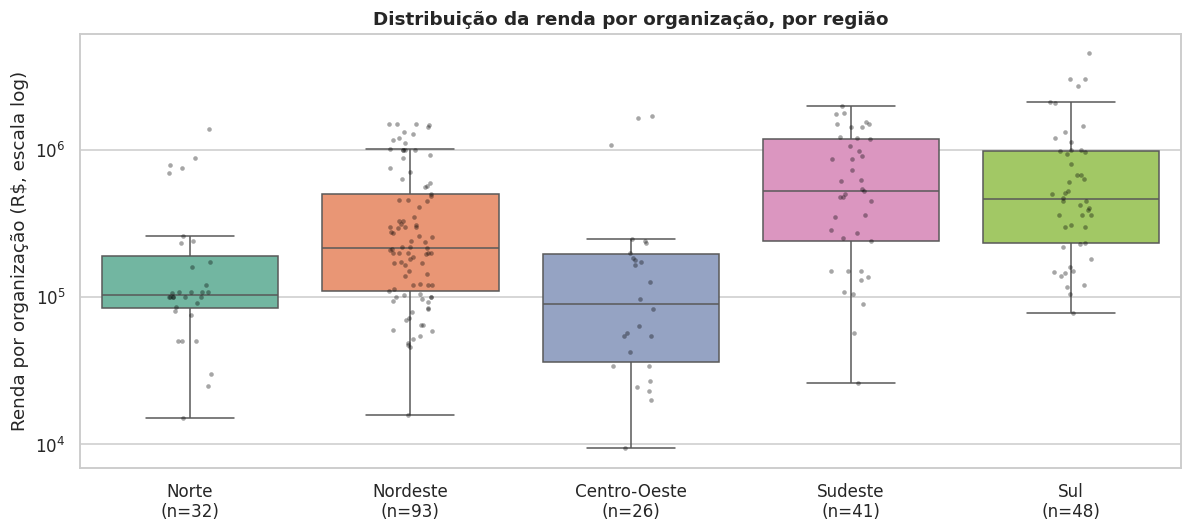

In [ ]:
cor_reg = dict(zip(ORDEM_REG, sns.color_palette('Set2', 5)))
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# A – renda total
a = ax[0, 0]
b = a.bar(reg.index, reg['RENDA_TOTAL'] / 1e6, color=[cor_reg[r] for r in reg.index])
for rect, p in zip(b, reg['PCT_RENDA']):
    a.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 0.3, f'{p:.1f}%', ha='center', fontsize=10, fontweight='bold')
a.set(ylabel='R$ milhões', title='A. Renda total por região (% do total)')

# B – média e mediana por organização
a = ax[0, 1]
x = np.arange(len(reg))
a.bar(x - 0.2, reg['MEDIA'] / 1e3, 0.38, color='#c0392b', label='Média')
a.bar(x + 0.2, reg['MEDIANA'] / 1e3, 0.38, color='#2b5c8f', label='Mediana')
a.set_xticks(x)
a.set_xticklabels(reg.index)
a.set(ylabel='R$ mil por organização', title='B. Renda por organização')
a.legend()

# C – % das organizações vs % da renda
a = ax[1, 0]
a.bar(x - 0.2, reg['PCT_ORGS'], 0.38, color='#7a9cc6', label='% das organizações')
a.bar(x + 0.2, reg['PCT_RENDA'], 0.38, color='#2b5c8f', label='% da renda')
a.set_xticks(x)
a.set_xticklabels(reg.index)
a.yaxis.set_major_formatter(mtick.PercentFormatter())
a.set_title('C. Presença de organizações vs. participação na renda')
a.legend()

# D – renda per capita
a = ax[1, 1]
b = a.bar(reg.index, reg['RENDA_PER_CAPITA'], color=[cor_reg[r] for r in reg.index])
for rect in b:
    a.text(rect.get_x() + rect.get_width() / 2, rect.get_height(), f'R$ {rect.get_height():.2f}'.replace('.', ','),
           ha='center', va='bottom', fontsize=10, fontweight='bold')
a.set(ylabel='R$ por habitante', title='D. Renda per capita (população Censo 2022)')
plt.tight_layout()
plt.show()

# Renda por beneficiário atendido e por fornecedor individual (aba CONTRATAÇÕES)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col, tit, yl in [(a1, 'RENDA_POR_BENEFICIARIO', 'Renda por beneficiário atendido (previsto)', 'R$ por beneficiário'),
                        (a2, 'RENDA_POR_FORNECEDOR', 'Renda por fornecedor individual (previsto)', 'R$ por fornecedor')]:
    b = a.bar(reg.index, reg[col], color=[cor_reg[r] for r in reg.index])
    for rect in b:
        a.text(rect.get_x() + rect.get_width() / 2, rect.get_height(), brl(rect.get_height(), 0), ha='center', va='bottom', fontsize=9)
    a.set(ylabel=yl, title=tit)
    a.tick_params(axis='x', labelsize=9)
plt.tight_layout()
plt.show()

# Distribuição por organização em cada região (escala log)
plt.figure(figsize=(11, 5))
sns.boxplot(data=org_reg, x='REGIAO', y='RENDA', order=ORDEM_REG, palette=cor_reg, showfliers=False)
sns.stripplot(data=org_reg, x='REGIAO', y='RENDA', order=ORDEM_REG, color='black', alpha=.35, size=3)
plt.yscale('log')
plt.xticks(range(5), [f'{r}\n(n={int(reg.loc[r, "N_ORGS"])})' for r in ORDEM_REG])
plt.xlabel('')
plt.ylabel('Renda por organização (R$, escala log)')
plt.title('Distribuição da renda por organização, por região')
plt.tight_layout()
plt.show()

**Análise dos gráficos.**

*A. Renda total:* Sul R\$ 38,8 mi (32,6%), Nordeste R\$ 37,3 mi (31,3%), Sudeste R\$ 28,9 mi (24,3%), Norte R\$ 7,4 mi (6,2%) e Centro-Oeste R\$ 6,8 mi (5,7%). Sul e Nordeste praticamente empatam; a assimetria entre regiões não aparece no total.

*B. Média e mediana por organização:* a mediana é de R\$ 525 mil no Sudeste e R\$ 459 mil no Sul, contra R\$ 215 mil no Nordeste, R\$ 103 mil no Norte e R\$ 90 mil no Centro-Oeste. A média do Sul (R\$ 809 mil) é 1,76 vez a mediana (efeito das grandes cooperativas gaúchas); no Sudeste, 1,34x.

*C. Organizações vs. renda:* o Nordeste tem 38,8% das organizações e 31,3% da renda; Norte (13,3% → 6,2%) e Centro-Oeste (10,8% → 5,7%) recebem cerca de metade do que sua presença em número sugeriria; Sul (20,0% → 32,6%) e Sudeste (17,1% → 24,3%) recebem mais que sua presença.

*D. Per capita:* Sul R\$ 1,30, Nordeste R\$ 0,68, Norte e Centro-Oeste R\$ 0,42, Sudeste R\$ 0,34. O Sul tem cerca de 15% da população e 32,6% da renda; o Sudeste, cerca de 42% da população e 24,3% da renda (população aproximada do Censo 2022).

*Leitura crítica:* os painéis contam histórias diferentes: o total (A) quase não mostra assimetria; por organização (B, C) ela é forte; per capita (D) ela vale para o Sul, mas não para o Sudeste. Por isso **nenhum indicador isolado resume "quem é favorecido"**.

**Beneficiários e fornecedores.** O Nordeste concentra **37,4%** dos beneficiários previstos e recebe 31,3% da renda; o Sul tem 27,3% dos beneficiários e 32,6% da renda. Por beneficiário, o recurso é maior no Centro-Oeste (R\$ 166) e no Norte (R\$ 106) e menor no Nordeste (R\$ 68). Por fornecedor individual, o valor varia menos: de R\$ 10,4 mil (Norte) a R\$ 16,7 mil (Sudeste). O que varia muito é o **nº de fornecedores por organização**: Sul 51,9; Sudeste 42,3; Nordeste 29,4; Norte 22,2; Centro-Oeste 18,8. A diferença regional por organização (cerca de 5x entre medianas) é, portanto, muito maior que a diferença por fornecedor (cerca de 1,6x): é uma questão de escala.

**Boxplot.** As distribuições regionais se sobrepõem bastante em escala logarítmica: há organizações do Nordeste com renda alta e do Sul com renda baixa. A região, sozinha, explica pouco da renda de uma organização (R² de 0,15 na regressão da seção 7.7).

### 7.3 Testes estatísticos
Como a renda por organização é muito assimétrica, usam-se testes **não paramétricos**: Kruskal-Wallis (as cinco regiões têm a mesma distribuição?) e Mann-Whitney (Sul+Sudeste recebem mais por organização que Norte+Nordeste?).

Kruskal-Wallis (5 regiões): H = 50.49, p = 0.0000 -> há diferença significativa (α = 5%)
Mann-Whitney (Sul+Sudeste > Norte+Nordeste): p = 0.0000 -> hipótese sustentada (α = 5%)
Mediana por organização: Sul+Sudeste = R$ 499.530,38 | Norte+Nordeste = R$ 196.997,76
Média por organização  : Sul+Sudeste = R$ 761.169,95 | Norte+Nordeste = R$ 357.362,46

P-valores ajustados (Bonferroni) entre pares de regiões:


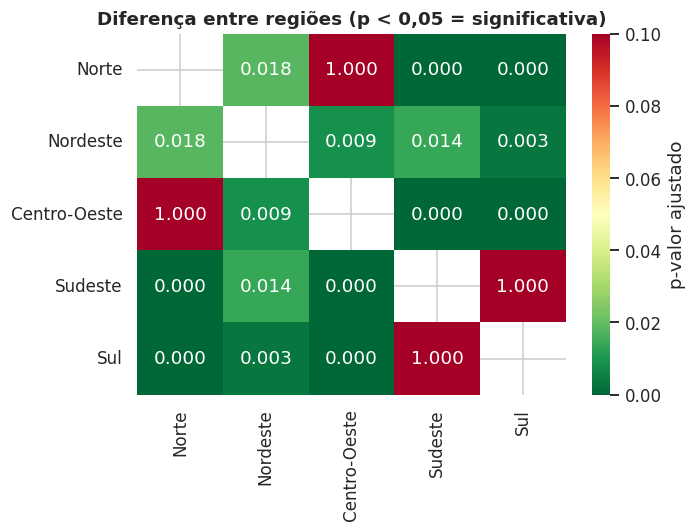

,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
Norte,NaN,0.0183,1.0000,0.0000,0.0000
Nordeste,0.0183,NaN,0.0087,0.0139,0.0033
Centro-Oeste,1.0000,0.0087,NaN,0.0003,0.0000
Sudeste,0.0000,0.0139,0.0003,NaN,1.0000
Sul,0.0000,0.0033,0.0000,1.0000,NaN


In [ ]:
# Há diferença estatisticamente significativa entre as regiões? (testes não paramétricos: renda é muito assimétrica)
grupos_reg = [org_reg.loc[org_reg['REGIAO'] == r, 'RENDA'] for r in ORDEM_REG]
H, p_kw = stats.kruskal(*grupos_reg)
print(f'Kruskal-Wallis (5 regiões): H = {H:.2f}, p = {p_kw:.4f} -> '
      f'{"há diferença significativa" if p_kw < 0.05 else "NÃO há diferença significativa"} (α = 5%)')

sul_sud = org_reg.loc[org_reg['REGIAO'].isin(['Sul', 'Sudeste']), 'RENDA']
n_ne = org_reg.loc[org_reg['REGIAO'].isin(['Norte', 'Nordeste']), 'RENDA']
U, p_mw = stats.mannwhitneyu(sul_sud, n_ne, alternative='greater')
print(f'Mann-Whitney (Sul+Sudeste > Norte+Nordeste): p = {p_mw:.4f} -> '
      f'{"hipótese sustentada" if p_mw < 0.05 else "hipótese NÃO sustentada"} (α = 5%)')
print(f'Mediana por organização: Sul+Sudeste = {brl(sul_sud.median())} | Norte+Nordeste = {brl(n_ne.median())}')
print(f'Média por organização  : Sul+Sudeste = {brl(sul_sud.mean())} | Norte+Nordeste = {brl(n_ne.mean())}')

# Comparações par a par entre regiões (Mann-Whitney com correção de Bonferroni)
from itertools import combinations
pares = list(combinations(ORDEM_REG, 2))
res = []
for a_, b_ in pares:
    ga = org_reg.loc[org_reg['REGIAO'] == a_, 'RENDA']
    gb = org_reg.loc[org_reg['REGIAO'] == b_, 'RENDA']
    res.append(stats.mannwhitneyu(ga, gb, alternative='two-sided').pvalue)
matriz = pd.DataFrame(np.nan, index=ORDEM_REG, columns=ORDEM_REG)
for (a_, b_), p in zip(pares, res):
    matriz.loc[a_, b_] = matriz.loc[b_, a_] = min(1.0, p * len(pares))
plt.figure(figsize=(6.5, 5))
sns.heatmap(matriz, annot=True, fmt='.3f', cmap='RdYlGn_r', vmin=0, vmax=0.1, cbar_kws={'label': 'p-valor ajustado'})
plt.title('Diferença entre regiões (p < 0,05 = significativa)')
plt.tight_layout()
plt.show()

print('\nP-valores ajustados (Bonferroni) entre pares de regiões:')
display(matriz.round(4))

**Análise dos testes.** O teste de Kruskal-Wallis confirma que as cinco regiões **não têm a mesma distribuição** (H = 50,5; p < 0,001), e o teste Sul+Sudeste > Norte+Nordeste é significativo (p < 0,001; mediana R\$ 499 mil vs. R\$ 197 mil).

*Leitura da matriz par a par (Bonferroni):* as regiões formam **três blocos**. Norte e Centro-Oeste não se distinguem entre si (p = 1,00); Sudeste e Sul também não (p = 1,00). O Nordeste fica no meio e difere de todas as outras (p entre 0,003 e 0,018), inclusive do Norte (p = 0,018). Duas consequências para a hipótese: (1) o agrupamento "Norte/Nordeste" é aproximado, porque o Nordeste está estatisticamente acima do Norte; (2) o **Centro-Oeste pertence ao bloco de baixa renda por organização**, e não ao grupo Sul/Sudeste como o senso comum sugeriria.

### 7.4 Renda por UF

3 UFs com maior renda: RS (21.6%), SP (12.3%), BA (11.7%)
UFs sem nenhuma contratação: []
Mapa geográfico indisponível (ModuleNotFoundError); exibindo mapa esquemático em grade.


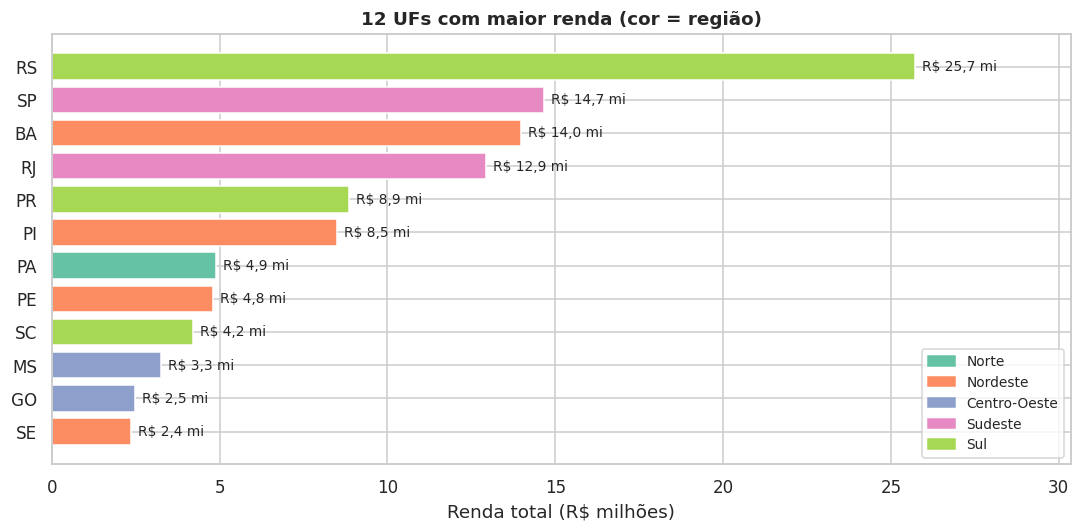

,UF,REGIAO,RENDA,PCT,ORGS,MEDIA_ORG
0,RS,Sul,"R$ 25.721.851,01",21.6%,20,"R$ 1.286.092,55"
1,SP,Sudeste,"R$ 14.659.765,74",12.3%,17,"R$ 862.339,16"
2,BA,Nordeste,"R$ 13.973.030,80",11.7%,24,"R$ 582.209,62"
3,RJ,Sudeste,"R$ 12.948.764,06",10.9%,15,"R$ 863.250,94"
4,PR,Sul,"R$ 8.869.034,93",7.4%,20,"R$ 443.451,75"
5,PI,Nordeste,"R$ 8.497.256,02",7.1%,21,"R$ 404.631,24"
6,PA,Norte,"R$ 4.894.777,14",4.1%,7,"R$ 699.253,88"
7,PE,Nordeste,"R$ 4.798.176,16",4.0%,8,"R$ 599.772,02"


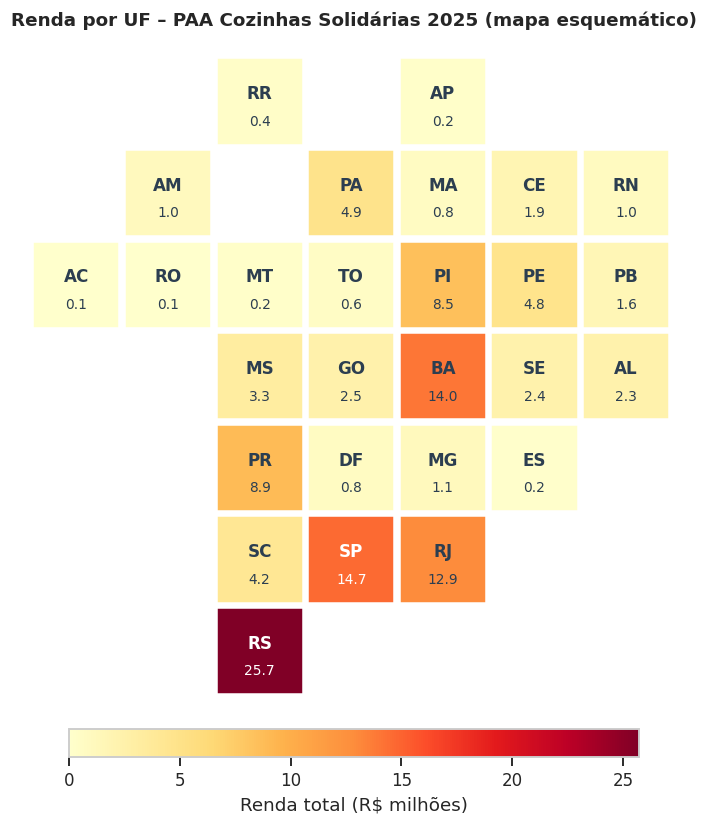

In [ ]:
renda_uf = df.groupby('UF')['VALOR'].sum().sort_values(ascending=False)

# Ranking das UFs
top = renda_uf.head(12).iloc[::-1]
plt.figure(figsize=(10, 5))
plt.barh(top.index, top.values / 1e6, color=[cor_reg[UF_REGIAO[u]] for u in top.index])
for i, v in enumerate(top.values):
    plt.text(v / 1e6 + 0.2, i, f'R$ {v / 1e6:,.1f} mi'.replace('.', ','), va='center', fontsize=9)
plt.xlim(0, top.max() / 1e6 * 1.18)
plt.xlabel('Renda total (R$ milhões)')
plt.title('12 UFs com maior renda (cor = região)')
plt.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in cor_reg.values()], cor_reg.keys(), loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

tab_uf = (df.groupby('UF').agg(RENDA=('VALOR', 'sum'), ORGS=('ORG_ID', 'nunique')).assign(REGIAO=lambda d: d.index.map(UF_REGIAO))
            .assign(PCT=lambda d: d['RENDA'] / d['RENDA'].sum() * 100, MEDIA_ORG=lambda d: d['RENDA'] / d['ORGS']).sort_values('RENDA', ascending=False))
mostrar(tab_uf.head(8).reset_index()[['UF', 'REGIAO', 'RENDA', 'PCT', 'ORGS', 'MEDIA_ORG']], brl_cols=['RENDA', 'MEDIA_ORG'], pct_cols=['PCT'])
print(f'3 UFs com maior renda: ' + ', '.join(f'{u} ({v / renda_uf.sum():.1%})' for u, v in renda_uf.head(3).items()))
print(f'UFs sem nenhuma contratação: {sorted(set(UF_REGIAO) - set(renda_uf.index))}')

# Mapa por UF
def mapa_grade(renda_uf):
    """Mapa esquemático: cada quadrado é uma UF, posicionado aproximadamente como no território."""
    pos = {'RR': (2, 0), 'AP': (4, 0), 'AM': (1, 1), 'PA': (3, 1), 'MA': (4, 1), 'CE': (5, 1), 'RN': (6, 1),
           'AC': (0, 2), 'RO': (1, 2), 'MT': (2, 2), 'TO': (3, 2), 'PI': (4, 2), 'PE': (5, 2), 'PB': (6, 2),
           'MS': (2, 3), 'GO': (3, 3), 'BA': (4, 3), 'SE': (5, 3), 'AL': (6, 3),
           'PR': (2, 4), 'DF': (3, 4), 'MG': (4, 4), 'ES': (5, 4), 'SC': (2, 5), 'SP': (3, 5), 'RJ': (4, 5), 'RS': (2, 6)}
    cmap, vmax = plt.cm.YlOrRd, renda_uf.max() / 1e6
    fig, ax = plt.subplots(figsize=(9, 8))
    for uf, (cx, cy) in pos.items():
        v = renda_uf.get(uf, 0) / 1e6
        ax.add_patch(plt.Rectangle((cx, -cy), 0.94, 0.94, color=cmap(v / vmax), ec='white'))
        ax.text(cx + .47, -cy + .55, uf, ha='center', va='center', fontsize=11, fontweight='bold', color='white' if v / vmax > .55 else '#2c3e50')
        ax.text(cx + .47, -cy + .25, f'{v:.1f}', ha='center', va='center', fontsize=9, color='white' if v / vmax > .55 else '#2c3e50')
    ax.set(xlim=(-.2, 7.2), ylim=(-6.2, 1.2), aspect='equal')
    ax.axis('off')
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, vmax))
    fig.colorbar(sm, ax=ax, orientation='horizontal', shrink=.6, pad=.02).set_label('Renda total (R$ milhões)')
    ax.set_title('Renda por UF – PAA Cozinhas Solidárias 2025 (mapa esquemático)', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()


try:   # mapa geográfico real (requer geopandas e internet; disponível no Colab)
    import geopandas as gpd
    url_geo = 'https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/brazil-states.geojson'
    gdf = gpd.read_file(url_geo).merge(renda_uf.rename('RENDA').reset_index(), left_on='sigla', right_on='UF', how='left')
    gdf['RENDA'] = gdf['RENDA'].fillna(0) / 1e6
    fig, ax = plt.subplots(figsize=(9, 9), dpi=120)
    gdf.plot(column='RENDA', cmap='YlOrRd', linewidth=.6, edgecolor='black', ax=ax)
    for _, r in gdf.iterrows():
        c = r.geometry.centroid
        ax.annotate(r['sigla'], (c.x, c.y), ha='center', va='center', fontsize=7, fontweight='bold', color='#2c3e50')
    sm = plt.cm.ScalarMappable(cmap='YlOrRd', norm=plt.Normalize(0, gdf['RENDA'].max()))
    fig.colorbar(sm, ax=ax, orientation='horizontal', shrink=.7, pad=.02).set_label('Renda total (R$ milhões)')
    ax.set_title('Renda por UF – PAA Cozinhas Solidárias 2025', fontsize=13, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f'Mapa geográfico indisponível ({type(e).__name__}); exibindo mapa esquemático em grade.')
    mapa_grade(renda_uf)

**Análise do ranking e do mapa.** *O que mostra:* Rio Grande do Sul (21,6%; R\$ 25,7 mi, 20 organizações), São Paulo (12,3%), Bahia (11,7%) e Rio de Janeiro (10,9%) somam 56,5% da renda. Em seguida vêm Paraná (7,4%) e Piauí (7,1%). Nenhuma UF ficou sem contratação.

*Leitura crítica:* (1) a **região esconde estados muito diferentes**. O Sudeste aparece com 24,3% quase só por SP e RJ (23,2%); Minas Gerais e Espírito Santo somam cerca de R\$ 1,3 mi. Isso explica o baixo per capita do Sudeste, que é população de MG e ES sem contratos, e não um viés da política contra a região toda. (2) O Nordeste depende de Bahia e Piauí (60% da renda regional); o Piauí sozinho (R\$ 8,5 mi) supera todo o Norte (R\$ 7,4 mi). (3) O Rio Grande do Sul tem a maior média por organização (R\$ 1,29 mi), quase o triplo da do Paraná (R\$ 443 mil), de modo que "Sul" não é um bloco homogêneo. (4) O mapa mostra a mesma coisa de forma territorial: o Sul e o litoral SP–RJ–BA são o centro de gravidade; Norte e Centro-Oeste ficam quase em branco, com exceção do Pará e do Mato Grosso do Sul.

### 7.5 Capacidade institucional: cooperativismo
Usa-se a **forma jurídica oficial** (cooperativa ou associação, aba CONTRATAÇÕES) como indicador da capacidade institucional: cooperativas formais tendem a atender melhor às exigências documentais e logísticas da CONAB.

Mann-Whitney (cooperativas recebem mais que associações): p = 0.0048


,Forma,count,mean,median,sum
0,Associações,112,"R$ 380.862,91","R$ 198.369,03","R$ 42.656.645,46"
1,Cooperativas,128,"R$ 598.053,36","R$ 319.917,18","R$ 76.550.830,68"


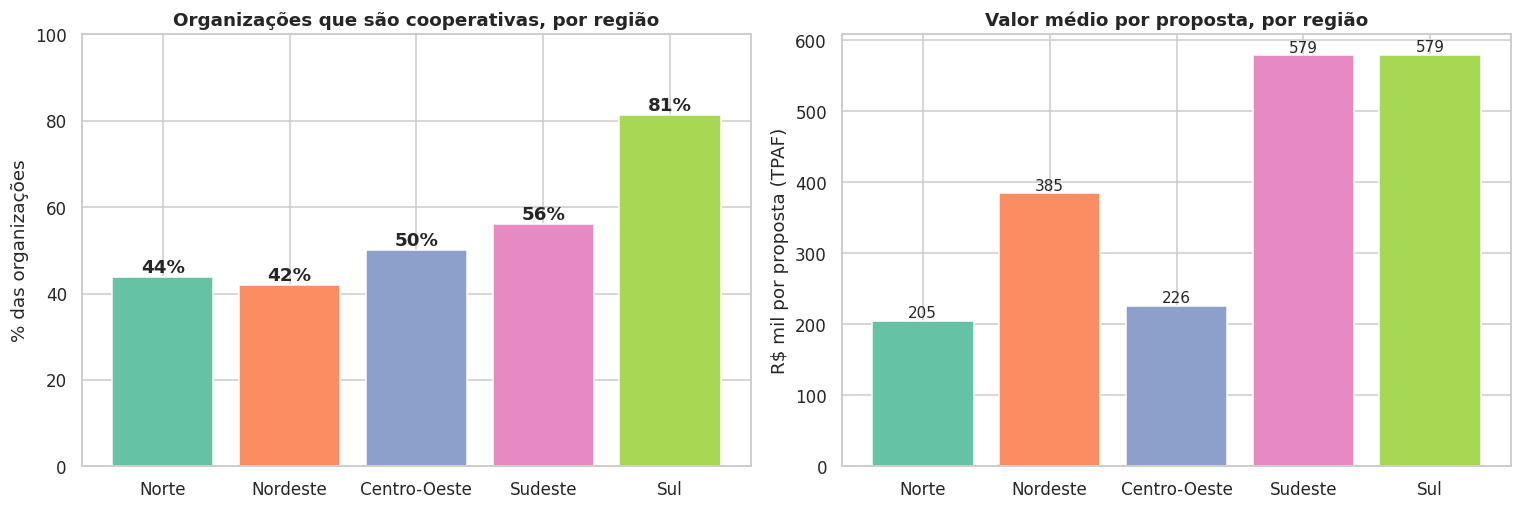

In [ ]:
# Forma jurídica oficial (aba CONTRATAÇÕES): cooperativa x associação
coop_global = org_reg.groupby('COOPERATIVA')['RENDA'].agg(['count', 'mean', 'median', 'sum'])
coop_global.index = coop_global.index.map({True: 'Cooperativas', False: 'Associações'})
mostrar(coop_global.reset_index().rename(columns={'COOPERATIVA': 'Forma'}), brl_cols=['mean', 'median', 'sum'])

U_c, p_c = stats.mannwhitneyu(org_reg.loc[org_reg['COOPERATIVA'], 'RENDA'], org_reg.loc[~org_reg['COOPERATIVA'], 'RENDA'], alternative='greater')
print(f'Mann-Whitney (cooperativas recebem mais que associações): p = {p_c:.4f}')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
a1.bar(reg.index, reg['PCT_COOP'], color=[cor_reg[r] for r in reg.index])
for i, v in enumerate(reg['PCT_COOP']):
    a1.text(i, v + 1, f'{v:.0f}%', ha='center', fontweight='bold')
a1.set(ylim=(0, 100), ylabel='% das organizações', title='Organizações que são cooperativas, por região')

b = a2.bar(reg.index, reg['TICKET_PROPOSTA'] / 1e3, color=[cor_reg[r] for r in reg.index])
for rect in b:
    if not np.isnan(rect.get_height()):
        a2.text(rect.get_x() + rect.get_width() / 2, rect.get_height(), f'{rect.get_height():,.0f}'.replace(',', '.'),
                ha='center', va='bottom', fontsize=10)
a2.set(ylabel='R$ mil por proposta (TPAF)', title='Valor médio por proposta, por região')
plt.tight_layout()
plt.show()

**Análise dos gráficos.** *Cooperativas vs. associações:* são 128 cooperativas (53,3% das organizações), com 64,2% da renda; a mediana é R\$ 320 mil nas cooperativas e R\$ 198 mil nas associações (p = 0,005). *Por região:* o Sul tem 81% de cooperativas, o Sudeste 56%, o Centro-Oeste 50%, o Norte 44% e o Nordeste 42%. O valor médio por proposta é R\$ 579 mil no Sul e no Sudeste, R\$ 385 mil no Nordeste, R\$ 226 mil no Centro-Oeste e R\$ 205 mil no Norte.

*Leitura crítica:* a relação entre **proporção de cooperativas e renda não é monotônica**. O Nordeste tem a menor proporção de cooperativas (42%), mas valor por proposta maior que o do Centro-Oeste e do Norte, que têm proporção maior (50% e 44%). O Sudeste tem proporção de cooperativas próxima à do Centro-Oeste (56% vs. 50%), mas valor por proposta 2,6x maior. Isso é coerente com o resultado da regressão: a diferença regional de renda **permanece quando se comparam organizações de mesma forma jurídica**. A forma cooperativa é uma vantagem individual (cooperativas recebem mais), mas não é o mecanismo principal da assimetria regional.

### 7.6 Alinhamento com a vulnerabilidade alimentar (INSAN)

In [ ]:
if INSAN_REGIAO:
    reg['INSAN'] = pd.Series(INSAN_REGIAO)
    rho, p = stats.spearmanr(reg['INSAN'], reg['RENDA_PER_CAPITA'])
    plt.figure(figsize=(7, 5))
    plt.scatter(reg['INSAN'], reg['RENDA_PER_CAPITA'], s=120, c=[cor_reg[r] for r in reg.index])
    for r, row in reg.iterrows():
        plt.annotate(r, (row['INSAN'], row['RENDA_PER_CAPITA']), xytext=(6, 6), textcoords='offset points')
    plt.xlabel('Insegurança alimentar (% dos domicílios)')
    plt.ylabel('Renda per capita do PAA (R$)')
    plt.title(f'Renda per capita × insegurança alimentar (Spearman ρ = {rho:.2f}, n = 5 regiões)')
    plt.tight_layout()
    plt.show()
    print('Função redistributiva exige correlação NEGATIVA entre INSAN e renda per capita. '
          f'Observado: ρ = {rho:.2f}. Com apenas 5 regiões, o teste tem baixíssimo poder estatístico.')
else:
    print('INSAN_REGIAO está vazio: preencha o dicionário na seção 7.1 para testar o alinhamento com a vulnerabilidade.')
    print('Enquanto isso, a comparação visual está no painel D (renda per capita por região).')

INSAN_REGIAO está vazio: preencha o dicionário na seção 7.1 para testar o alinhamento com a vulnerabilidade.
Enquanto isso, a comparação visual está no painel D (renda per capita por região).


### 7.7 Testes de robustez: o que explica as diferenças?
Antes de interpretar, três perguntas que os números brutos não respondem:

1. A desigualdade está **entre** regiões/tipos ou **dentro** deles? (decomposição do índice de Theil)
2. As diferenças regionais são de **porte** das organizações? (distribuição por faixa de valor e peso das maiores)
3. As diferenças (regionais e de gênero) **resistem a controles** por forma jurídica, tipo e número de fornecedores? (regressão de log da renda, erros robustos HC3)

> Nº de fornecedores é um controle de *escala*, mas também pode ser consequência da capacidade institucional (um mediador). Por isso os modelos são apresentados em etapas, para ver quanto cada controle altera o resultado.

RS: 20 organizações, R$ 25.721.851,01 (21.6% do total); as 3 maiores = 40.8% da renda do estado.
MQO de log(renda da organização), erros robustos (HC3). Efeito = variação % na renda para cada +10 p.p. de mulheres entre os fornecedores.
Se a diferença cai muito ao incluir porte, a vantagem do Sul/Sudeste é, em grande parte, uma diferença de escala das organizações (nº de fornecedores).
Correlação de Spearman entre renda da organização e nº de produtos distintos: ρ = -0.14 (p = 0.0348).


,Agrupamento,Theil total,% entre grupos,% dentro dos grupos
0,Região,0.552,16.8%,83.2%
1,Tipo de organização,0.552,3.9%,96.1%
2,Forma jurídica,0.552,4.4%,95.6%


RENDA,Região,até R$ 100 mil,R$ 100–300 mil,R$ 300 mil–1 mi,acima de R$ 1 mi
0,Norte,50.0%,34.4%,12.5%,3.1%
1,Nordeste,22.6%,39.8%,25.8%,11.8%
2,Centro-Oeste,53.8%,34.6%,0.0%,11.5%
3,Sudeste,7.3%,26.8%,36.6%,29.3%
4,Sul,2.1%,29.2%,47.9%,20.8%


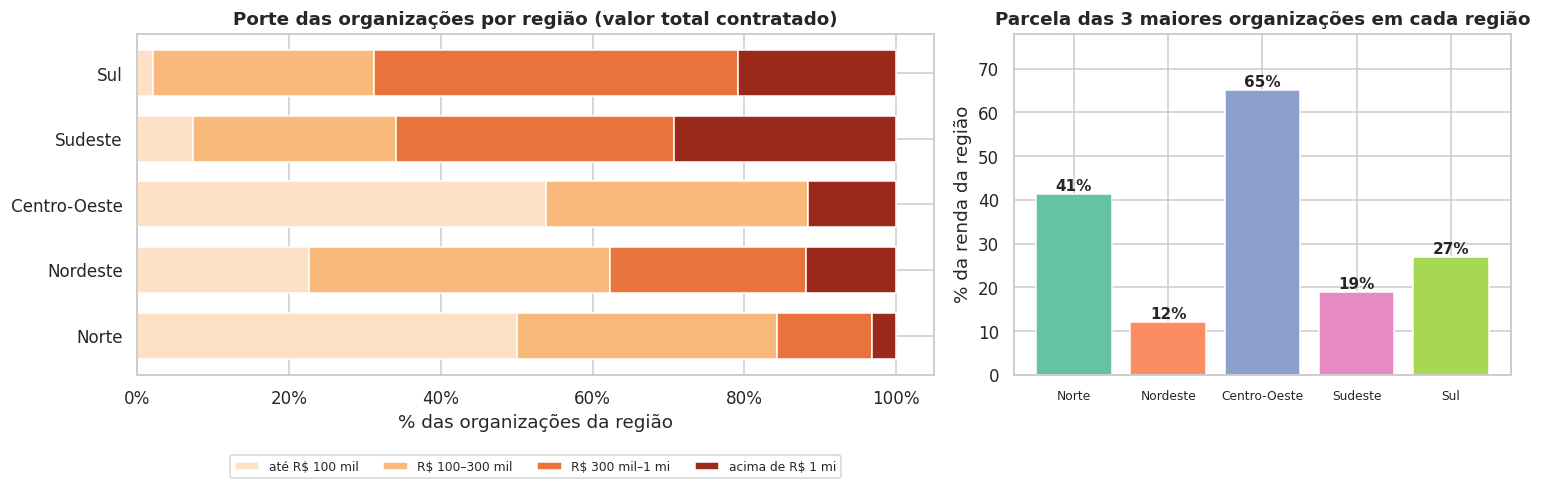

,Modelo,Efeito de +10 p.p. de mulheres na renda,p-valor,R²
0,Só % de mulheres,-17.0%,0.000,0.07
1,+ nº de fornecedores (porte),-1.8%,0.359,0.87
2,"+ região, tipo e cooperativa",-1.0%,0.606,0.88


,Modelo,Diferença na renda por organização,p-valor,R²
0,Sul/Sudeste vs. demais regiões (sem controles),+163%,0.000,0.15
1,+ cooperativa e tipo,+148%,0.000,0.17
2,+ nº de fornecedores (porte),+20%,0.006,0.88


,Modelo,"Produtos distintos, agricultores familiares vs. demais",p-valor,R²
0,Sem controle,+68%,0.001,0.05
1,+ renda da organização (porte),+61%,0.002,0.06


In [ ]:
# 9.1 Desigualdade ENTRE grupos ou DENTRO deles? (decomposição do índice de Theil)
def theil(v):
    v = np.asarray(v, dtype=float)
    m = v.mean()
    return np.mean((v / m) * np.log(v / m))


def decompor_theil(d, grupo):
    """T total = T entre grupos + T dentro dos grupos (ponderado pela participação na renda)."""
    total = d['RENDA'].sum()
    dentro = sum(g['RENDA'].sum() / total * theil(g['RENDA']) for _, g in d.groupby(grupo))
    return theil(d['RENDA']), theil(d['RENDA']) - dentro, dentro


base_org = org_reg.merge(df.drop_duplicates('ORG_ID')[['ORG_ID', 'TIPO']], on='ORG_ID')
linhas = []
for nome, col in [('Região', 'REGIAO'), ('Tipo de organização', 'TIPO'), ('Forma jurídica', 'COOPERATIVA')]:
    T, entre, dentro = decompor_theil(base_org, col)
    linhas.append({'Agrupamento': nome, 'Theil total': T, '% entre grupos': entre / T * 100, '% dentro dos grupos': dentro / T * 100})
decomp = pd.DataFrame(linhas)
mostrar(decomp, dec_cols=['Theil total'], pct_cols=['% entre grupos', '% dentro dos grupos'])

# 9.2 Perfil do porte das organizações por região (explica a assimetria? muitas organizações pequenas no N/NE?)
faixas = pd.cut(org_reg['RENDA'], [0, 1e5, 3e5, 1e6, np.inf], labels=['até R$ 100 mil', 'R$ 100–300 mil', 'R$ 300 mil–1 mi', 'acima de R$ 1 mi'])
porte = pd.crosstab(org_reg['REGIAO'], faixas, normalize='index').reindex(ORDEM_REG) * 100
top3 = org_reg.sort_values('RENDA', ascending=False).groupby('REGIAO').head(3).groupby('REGIAO')['RENDA'].sum() / reg['RENDA_TOTAL'] * 100

mostrar(porte.reset_index().rename(columns={'REGIAO': 'Região'}), pct_cols=list(porte.columns))
rs = df[df['UF'] == 'RS'].groupby('ORG_ID')['VALOR'].sum().sort_values(ascending=False)
print(f'RS: {len(rs)} organizações, {brl(rs.sum())} ({rs.sum() / df["VALOR"].sum():.1%} do total); as 3 maiores = {rs.head(3).sum() / rs.sum():.1%} da renda do estado.')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.6, 1]})
porte.plot(kind='barh', stacked=True, ax=a1, color=['#fde0c5', '#f9b97a', '#e8743b', '#9c2a1c'], width=.7)
a1.set(xlabel='% das organizações da região', ylabel='', title='Porte das organizações por região (valor total contratado)')
a1.xaxis.set_major_formatter(mtick.PercentFormatter())
a1.legend(fontsize=8, loc='lower center', bbox_to_anchor=(.5, -.32), ncol=4)
b = a2.bar(top3.reindex(ORDEM_REG).index, top3.reindex(ORDEM_REG).values, color=[cor_reg[r] for r in ORDEM_REG])
for rect in b:
    a2.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + .8, f'{rect.get_height():.0f}%', ha='center', fontsize=10, fontweight='bold')
a2.set(ylim=(0, 78), ylabel='% da renda da região', title='Parcela das 3 maiores organizações em cada região')
a2.tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.show()

# 9.3 O efeito "mais mulheres, menos renda" resiste ao controle por porte, região, tipo e forma jurídica?
def tipo_agrupado(t):
    """Tipos com menos de MIN_N organizações viram 'Outros' (evita variável indicadora de uma única observação)."""
    n = renda_org.groupby('TIPO')['ORG_ID'].nunique()
    return t.where(t.map(n) >= MIN_N, 'Outros')


def ols_hc3(y, X):
    """MQO com erros-padrão robustos HC3. Retorna coeficientes, p-valores e R²."""
    X = np.asarray(X, float); y = np.asarray(y, float)
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    e = y - X @ beta
    h = np.einsum('ij,jk,ik->i', X, XtX_inv, X)
    meat = X.T @ (X * (e ** 2 / (1 - h) ** 2)[:, None])
    se = np.sqrt(np.diag(XtX_inv @ meat @ XtX_inv))
    p = 2 * (1 - stats.t.cdf(np.abs(beta / se), df=len(y) - X.shape[1]))
    return beta, p, 1 - e.var() / y.var()


m = org_f.merge(df.drop_duplicates('ORG_ID')[['ORG_ID', 'TIPO', 'COOPERATIVA']], on='ORG_ID')
y = np.log(m['VALOR'])
base = pd.DataFrame({'const': 1.0, 'PCT_MULH': m['PCT_MULH']})
porte = pd.DataFrame({'LOG_FORNEC': np.log(m['FORNEC'])})
ctrl = pd.concat([pd.get_dummies(m['REGIAO'], prefix='REG', drop_first=True),
                  pd.get_dummies(tipo_agrupado(m['TIPO']), prefix='TIPO', drop_first=True),
                  m['COOPERATIVA'].astype(float).rename('COOP')], axis=1).astype(float)
modelos = {'Só % de mulheres': base,
           '+ nº de fornecedores (porte)': pd.concat([base, porte], axis=1),
           '+ região, tipo e cooperativa': pd.concat([base, porte, ctrl], axis=1)}
res = []
for nome, X in modelos.items():
    beta, p, r2 = ols_hc3(y, X.values)
    b = beta[list(X.columns).index('PCT_MULH')]
    res.append({'Modelo': nome, 'Efeito de +10 p.p. de mulheres na renda': f'{(np.exp(b * 0.1) - 1) * 100:+.1f}%',
                'p-valor': f'{p[list(X.columns).index("PCT_MULH")]:.3f}', 'R²': f'{r2:.2f}'})
EF_MULH_CTRL = (np.exp(beta[list(X.columns).index('PCT_MULH')] * 0.1) - 1) * 100   # modelo completo (último do laço)
P_MULH_CTRL = p[list(X.columns).index('PCT_MULH')]
display(pd.DataFrame(res))
print('MQO de log(renda da organização), erros robustos (HC3). Efeito = variação % na renda para cada +10 p.p. de mulheres entre os fornecedores.')


# 9.4 A vantagem do Sul/Sudeste por organização some quando se compara organizações de mesma forma jurídica, tipo e porte?
forn = contr.groupby(['ORG_ID', 'REGIAO'])['FORNECEDORES'].sum().rename('FORNEC').reset_index()
r = org_reg.merge(base_org[['ORG_ID', 'REGIAO', 'TIPO']], on=['ORG_ID', 'REGIAO']).merge(forn, on=['ORG_ID', 'REGIAO'])
r = r[r['FORNEC'] > 0]
y = np.log(r['RENDA'])
sul = pd.DataFrame({'const': 1.0, 'SUL_SUDESTE': r['REGIAO'].isin(['Sul', 'Sudeste']).astype(float)})
coop_d = r[['COOPERATIVA']].astype(float).rename(columns={'COOPERATIVA': 'COOP'})
tipo_d = pd.get_dummies(tipo_agrupado(r['TIPO']), prefix='TIPO', drop_first=True).astype(float)
porte_d = pd.DataFrame({'LOG_FORNEC': np.log(r['FORNEC'])})
mods = {'Sul/Sudeste vs. demais regiões (sem controles)': sul,
        '+ cooperativa e tipo': pd.concat([sul, coop_d, tipo_d], axis=1),
        '+ nº de fornecedores (porte)': pd.concat([sul, coop_d, tipo_d, porte_d], axis=1)}
res2 = []
for nome, X in mods.items():
    beta, p, r2 = ols_hc3(y, X.values)
    k = list(X.columns).index('SUL_SUDESTE')
    res2.append({'Modelo': nome, 'Diferença na renda por organização': f'{(np.exp(beta[k]) - 1) * 100:+.0f}%',
                 'p-valor': f'{p[k]:.3f}', 'R²': f'{r2:.2f}'})
display(pd.DataFrame(res2))
print('Se a diferença cai muito ao incluir porte, a vantagem do Sul/Sudeste é, em grande parte, uma diferença de escala das organizações (nº de fornecedores).')


# 9.5 A maior variedade de produtos dos agricultores familiares é só efeito de porte?
v = renda_org[renda_org['TIPO'].isin(resumo.loc[resumo['N_ORGS'] >= MIN_N, 'TIPO'])].copy()
y = np.log(v['PRODUTOS_DISTINTOS'])
X1 = pd.DataFrame({'const': 1.0, 'AGRIC_FAMILIAR': (v['TIPO'] == 'Agricultores familiares').astype(float)})
X2 = pd.concat([X1, pd.DataFrame({'LOG_RENDA': np.log(v['RENDA'])})], axis=1)
res3 = []
for nome, X in {'Sem controle': X1, '+ renda da organização (porte)': X2}.items():
    beta, p, r2 = ols_hc3(y, X.values)
    res3.append({'Modelo': nome, 'Produtos distintos, agricultores familiares vs. demais': f'{(np.exp(beta[1]) - 1) * 100:+.0f}%',
                 'p-valor': f'{p[1]:.3f}', 'R²': f'{r2:.2f}'})
display(pd.DataFrame(res3))
rho_v, p_v = stats.spearmanr(v['RENDA'], v['PRODUTOS_DISTINTOS'])
print(f'Correlação de Spearman entre renda da organização e nº de produtos distintos: ρ = {rho_v:.2f} (p = {p_v:.4f}).')

**Análise dos testes de robustez.**

*Theil (desigualdade entre vs. dentro):* 83% da desigualdade está dentro das regiões e só 17% entre elas; por tipo, 96% é interna; por forma jurídica, 96%. Ou seja, **dois agrupamentos de organizações da mesma região, do mesmo tipo ou da mesma forma jurídica diferem tanto entre si quanto organizações quaisquer**.

*Porte e peso das maiores:* 50% das organizações do Norte e 54% das do Centro-Oeste recebem até R\$ 100 mil, contra 23% no Nordeste, 7% no Sudeste e 2% no Sul. No Sul e no Sudeste, a faixa dominante é de R\$ 300 mil a R\$ 1 mi (48% e 37%) e 21% e 29% das organizações passam de R\$ 1 mi. As 3 maiores organizações representam 65% da renda do Centro-Oeste, 41% do Norte, 27% do Sul, 19% do Sudeste e só 12% do Nordeste: o Nordeste é a base mais diversificada, e o Centro-Oeste e o Norte dependem de poucos contratos.

*Regressões:* (a) **mulheres:** o efeito de +10 p.p. de mulheres cai de −17,0% (p < 0,001) para −1,8% (p = 0,36) ao controlar pelo nº de fornecedores e para −1,0% (p = 0,61) com região, tipo e cooperativa. (b) **Sul/Sudeste:** a vantagem de +163% quase não muda com cooperativa e tipo (+148%), mas cai para +20% (p = 0,006) com o nº de fornecedores. (c) **variedade:** a vantagem dos agricultores familiares (+68%) praticamente se mantém com o controle de porte (+61%).

*Leitura crítica:* o nº de fornecedores é, ao mesmo tempo, controle de escala e possível resultado da capacidade institucional; portanto, os modelos mostram **onde** a diferença está (escala), mas não **por quê**. O R² de 0,87–0,89 nos modelos com porte mostra que o nº de fornecedores explica quase toda a variação de renda entre organizações, e isso é em parte tautológico: mais fornecedores significa mais produto a entregar.

## 8. Verificação das afirmações com os dados

A tabela abaixo confronta cada afirmação feita na análise e na discussão com os números calculados nas seções anteriores. O veredito é calculado automaticamente a cada execução:

- ✅ **Confirmada:** os dados sustentam a afirmação.
- ⚠️ **Parcial:** a direção está correta, mas a magnitude ou a significância estatística é insuficiente.
- ❌ **Não confirmada:** os dados não sustentam a afirmação (ou apontam o contrário).

**Critérios usados nos vereditos.** Os limiares são escolhas do autor e podem ser revistos conforme o objetivo do estudo:

| Afirmação | ✅ Confirmada se | ⚠️ Parcial se |
|---|---|---|
| Sul concentra a maior renda | Sul é a região com maior total | Sul está entre as duas maiores |
| Valor por organização maior no Sul/Sudeste | Mann-Whitney p < 0,05 | Mediana maior, sem significância |
| Per capita do Sul (ou Sudeste) maior que N/NE | Pelo menos 20% acima do maior valor entre Norte e Nordeste | Acima, mas por menos de 20% |
| Recurso por beneficiário maior no Sul/Sudeste | O menor entre Sul e Sudeste supera o maior entre Norte e Nordeste | Média de Sul/Sudeste maior |
| Agricultores concentram o volume | É o tipo com maior renda | — |
| Agricultores têm maior variedade | Maior que todos os outros tipos com n ≥ 10 | Maior que a média dos outros |
| Povos tradicionais com participação pequena | < 5% da renda | % da renda menor que % das organizações |
| Mulheres com baixa participação | < 30% dos fornecedores | < 50% |
| Organizações femininas recebem menos | p < 0,05, mediana ≥ 30% menor **e** efeito significativo após controle de porte (seção 7.7) | p < 0,05 ou mediana menor |
| Média supera a mediana | Em todos os tipos com n ≥ 10 e razão máxima > 1,5 | Em pelo menos um tipo |
| Renda concentrada | Gini ≥ 0,50 | Gini ≥ 0,40 |
| Mais cooperativas nas regiões de maior renda | Diferença > 10 p.p. e cooperativas com p < 0,05 | Diferença positiva |

In [ ]:
def veredito(confirmada, parcial=False):
    return '✅ Confirmada' if confirmada else ('⚠️ Parcial' if parcial else '❌ Não confirmada')


tipos_ok = resumo[resumo['N_ORGS'] >= MIN_N]
afirmacoes = []

# 1. Sul concentra a maior parte dos recursos
ordem_reg = reg['RENDA_TOTAL'].sort_values(ascending=False)
ss = reg.loc[['Sul', 'Sudeste'], 'PCT_RENDA'].sum()
nn = reg.loc[['Norte', 'Nordeste'], 'PCT_RENDA'].sum()
afirmacoes.append(('Região Sul concentra a maior renda total',
                   'Ranking: ' + ' > '.join(f'{r} ({reg.loc[r, "PCT_RENDA"]:.1f}%)' for r in ordem_reg.index[:3]) +
                   f' | Sul+Sudeste = {ss:.1f}% vs. Norte+Nordeste = {nn:.1f}%',
                   veredito(ordem_reg.index[0] == 'Sul', 'Sul' in ordem_reg.index[:2])))

# 2. Sul/Sudeste recebem mais por organização (hipótese de pesquisa)
afirmacoes.append(('Renda por organização é maior no Sul/Sudeste que no Norte/Nordeste',
                   f'Mediana: {brl(sul_sud.median())} vs. {brl(n_ne.median())} | Mann-Whitney p = {p_mw:.4f} | Kruskal-Wallis (5 regiões) p = {p_kw:.4f}',
                   veredito(p_mw < 0.05, sul_sud.median() > n_ne.median())))

# 3. Per capita (Sul e Sudeste avaliados separadamente: eles se comportam de forma diferente)
pc = reg['RENDA_PER_CAPITA']
ref = pc[['Norte', 'Nordeste']].max()
txt_pc = ' | '.join(f'{r}: {brl(pc[r])}' for r in ORDEM_REG)
afirmacoes.append(('Renda per capita do Sul é maior que a do Norte e do Nordeste', txt_pc, veredito(pc['Sul'] > ref * 1.2, pc['Sul'] > ref)))
afirmacoes.append(('Renda per capita do Sudeste é maior que a do Norte e do Nordeste', txt_pc, veredito(pc['Sudeste'] > ref * 1.2, pc['Sudeste'] > ref)))

# 4. Recursos por beneficiário atendido
rb = reg['RENDA_POR_BENEFICIARIO']
afirmacoes.append(('Recurso por beneficiário atendido é maior no Sul/Sudeste que no Norte/Nordeste',
                   ' | '.join(f'{r}: {brl(rb[r])}' for r in ORDEM_REG),
                   veredito(rb[['Sul', 'Sudeste']].min() > rb[['Norte', 'Nordeste']].max(), rb[['Sul', 'Sudeste']].mean() > rb[['Norte', 'Nordeste']].mean())))

# 5. Agricultores familiares concentram o volume ...
top_tipo = resumo.iloc[0]
afirmacoes.append(('Agricultores familiares concentram o maior volume financeiro',
                   f'Maior tipo: {top_tipo["TIPO"]} ({top_tipo["PCT_RENDA"]:.1f}% da renda, {top_tipo["PCT_ORGS"]:.1f}% das organizações)',
                   veredito(top_tipo['TIPO'] == 'Agricultores familiares')))

# 6. ... e fornecem maior variedade de produtos (só tipos com n suficiente)
af = tipos_ok.loc[tipos_ok['TIPO'] == 'Agricultores familiares', 'PRODUTOS_POR_ORG'].iloc[0]
outros = tipos_ok.loc[tipos_ok['TIPO'] != 'Agricultores familiares', 'PRODUTOS_POR_ORG']
afirmacoes.append(('Agricultores familiares fornecem maior variedade de produtos por organização',
                   f'{af:.1f} produtos/org vs. {", ".join(f"{t}: {v:.1f}" for t, v in zip(tipos_ok.loc[tipos_ok["TIPO"] != "Agricultores familiares", "TIPO"], outros))}',
                   veredito(af > outros.max(), af > outros.mean())))

# 7. Povos tradicionais com participação menor
trad = resumo[resumo['TIPO'].isin(['Quilombolas', 'Povos indígenas'])]
afirmacoes.append(('Quilombolas e povos indígenas têm participação financeira pequena',
                   f'{trad["PCT_RENDA"].sum():.2f}% da renda para {trad["PCT_ORGS"].sum():.1f}% das organizações ({trad["N_ORGS"].sum()} organizações); '
                   f'renda média/org = {brl(trad["RENDA_TOTAL"].sum() / trad["N_ORGS"].sum())} vs. {brl(renda_org["RENDA"].mean())} geral',
                   veredito(trad['PCT_RENDA'].sum() < 5, trad['PCT_RENDA'].sum() < trad['PCT_ORGS'].sum())))

# 8. Mulheres: participação e renda das organizações de maioria feminina
# (confirmada: diferença significativa e mediana ≥30% menor; parcial: significativa porém menor, ou menor sem significância)
pm = contr['MULHERES'].sum() / tot_forn * 100
afirmacoes.append(('Mulheres têm baixa participação entre os fornecedores',
                   f'{pm:.1f}% dos fornecedores previstos são mulheres ({contr["MULHERES"].sum():,.0f} de {tot_forn:,.0f})'.replace(',', '.'),
                   veredito(pm < 30, pm < 50)))
mm = org_f.loc[org_f['PRED_MULH'], 'VALOR'].median()
mh = org_f.loc[~org_f['PRED_MULH'], 'VALOR'].median()
afirmacoes.append(('Organizações predominantemente femininas (≥75% mulheres) recebem menos por organização',
                   f'Mediana: {brl(mm)} (predominantemente femininas, n={org_f["PRED_MULH"].sum()}) vs. {brl(mh)} (demais) | Mann-Whitney p = {p_f:.3f} | '
                   f'Spearman %mulheres × renda: ρ = {rho_f:.2f} | após controlar porte, região, tipo e cooperativa: {EF_MULH_CTRL:+.1f}% por +10 p.p. de mulheres (p = {P_MULH_CTRL:.2f})',
                   veredito(p_f < 0.05 and mm < 0.7 * mh and P_MULH_CTRL < 0.05, p_f < 0.05 or mm < mh)))

# 9. Média muito acima da mediana
razao = tipos_ok['MEDIA'] / tipos_ok['MEDIANA']
afirmacoes.append(('Média supera a mediana (efeito de organizações muito grandes)',
                   f'Razão média/mediana nos tipos com n ≥ {MIN_N}: de {razao.min():.2f}x a {razao.max():.2f}x',
                   veredito((razao > 1).all() and razao.max() > 1.5, (razao > 1).any())))

# 10. Concentração (limiar: Gini ≥ 0,50 = desigualdade alta, referência usual; ≥ 0,40 = parcial)
t10 = parcela_topo(valores, .10)
g_geral = gini(valores)
afirmacoes.append(('A renda é concentrada em poucas organizações',
                   f'Gini geral = {g_geral:.3f}; top 10% das organizações = {t10:.1%} da renda; 10 maiores = {parcela_topo(valores, 10 / len(valores)):.1%}',
                   veredito(g_geral >= 0.5, g_geral >= 0.4)))

# 11. Cooperativismo mais presente nas regiões de maior renda (forma jurídica oficial)
coop_top = reg.loc[ordem_reg.index[:2], 'PCT_COOP'].mean()
coop_rest = reg.loc[ordem_reg.index[2:], 'PCT_COOP'].mean()
afirmacoes.append(('Regiões de maior renda têm mais cooperativas',
                   f'% de cooperativas: 2 maiores regiões = {coop_top:.0f}% vs. demais = {coop_rest:.0f}% | cooperativas recebem mais por organização que associações (p = {p_c:.4f})',
                   veredito(coop_top > coop_rest + 10 and p_c < 0.05, coop_top > coop_rest)))

tab = pd.DataFrame(afirmacoes, columns=['Afirmação', 'Evidência nos dados', 'Veredito'])
pd.set_option('display.max_colwidth', None)
display(tab)
print('\nResumo:', tab['Veredito'].value_counts().to_dict())


Resumo: {'✅ Confirmada': 9, '❌ Não confirmada': 3, '⚠️ Parcial': 1}


,Afirmação,Evidência nos dados,Veredito
0,Região Sul concentra a maior renda total,Ranking: Sul (32.6%) > Nordeste (31.3%) > Sudeste (24.3%) | Sul+Sudeste = 56.8% vs. Norte+Nordeste = 37.5%,✅ Confirmada
1,Renda por organização é maior no Sul/Sudeste que no Norte/Nordeste,"Mediana: R$ 499.530,38 vs. R$ 196.997,76 | Mann-Whitney p = 0.0000 | Kruskal-Wallis (5 regiões) p = 0.0000",✅ Confirmada
2,Renda per capita do Sul é maior que a do Norte e do Nordeste,"Norte: R$ 0,42 | Nordeste: R$ 0,68 | Centro-Oeste: R$ 0,42 | Sudeste: R$ 0,34 | Sul: R$ 1,30",✅ Confirmada
3,Renda per capita do Sudeste é maior que a do Norte e do Nordeste,"Norte: R$ 0,42 | Nordeste: R$ 0,68 | Centro-Oeste: R$ 0,42 | Sudeste: R$ 0,34 | Sul: R$ 1,30",❌ Não confirmada
4,Recurso por beneficiário atendido é maior no Sul/Sudeste que no Norte/Nordeste,"Norte: R$ 106,41 | Nordeste: R$ 68,18 | Centro-Oeste: R$ 165,66 | Sudeste: R$ 71,03 | Sul: R$ 96,99",❌ Não confirmada
5,Agricultores familiares concentram o maior volume financeiro,"Maior tipo: Agricultores familiares (62.9% da renda, 66.0% das organizações)",✅ Confirmada
6,Agricultores familiares fornecem maior variedade de produtos por organização,"7.9 produtos/org vs. Assentados da reforma agrária: 5.6, Pescadores artesanais: 3.8",✅ Confirmada
7,Quilombolas e povos indígenas têm participação financeira pequena,"1.22% da renda para 2.9% das organizações (7 organizações); renda média/org = R$ 207.284,63 vs. R$ 488.555,23 geral",✅ Confirmada
8,Mulheres têm baixa participação entre os fornecedores,66.5% dos fornecedores previstos são mulheres (5.421 de 8.156),❌ Não confirmada
9,Organizações predominantemente femininas (≥75% mulheres) recebem menos por organização,"Mediana: R$ 154.977,50 (predominantemente femininas, n=90) vs. R$ 349.599,40 (demais) | Mann-Whitney p = 0.000 | Spearman %mulheres × renda: ρ = -0.27 | após controlar porte, região, tipo e cooperativa: -1.0% por +10 p.p. de mulheres (p = 0.61)",⚠️ Parcial


### 8.1 Principais achados (execução com a planilha CONAB enviada)

**Base:** R\$ 119,2 milhões em 280 propostas de 240 organizações (CNPJs) e 8.156 fornecedores individuais previstos. A linha de total removida na Seção 3 dobrava esse valor.

| # | Achado | Evidência |
|---|---|---|
| 1 | **A renda é concentrada e o Gini é alto.** | Gini ≈ 0,55; o top 10% das organizações fica com ~37% da renda e recebe 4,6 vezes o que os 40% menores recebem (Palma). As 10 maiores somam 20,6% do total. |
| 2 | **Agricultores familiares dominam e são o grupo mais desigual.** | 62,9% da renda e 66% das organizações; Gini 0,58 e Palma 5,6x; média 2,1 vezes a mediana. |
| 3 | **Quilombolas e indígenas têm participação mínima.** | 7 organizações (2,9%) com 1,22% da renda; média por organização de R\$ 207 mil vs. R\$ 489 mil geral. Como são poucas organizações, o dado descreve o caso e não permite inferência estatística. |
| 4 | **O Sul lidera por pouco no total, mas a diferença real é por organização.** | Sul 32,6% vs. Nordeste 31,3% da renda. Porém o Nordeste tem 38,8% das organizações e o Sul, 20%. Mediana por organização: R\$ 499 mil (Sul+Sudeste) vs. R\$ 197 mil (Norte+Nordeste), diferença significativa (p < 0,001). O Rio Grande do Sul sozinho concentra 21,6% da renda. |
| 5 | **Per capita, o Sul se destaca, mas o Sudeste não.** | Sul R\$ 1,30; Nordeste R\$ 0,68; Norte e Centro-Oeste R\$ 0,42; Sudeste R\$ 0,34 (o menor). |
| 6 | **Por beneficiário atendido, Sul/Sudeste não são favorecidos.** | Centro-Oeste R\$ 166; Norte R\$ 106; Sul R\$ 97; Sudeste R\$ 71; Nordeste R\$ 68 (o menor, apesar do maior número de beneficiários previstos). |
| 7 | **Cooperativas recebem mais, e o Sul é a região mais cooperativista.** | 81% das organizações do Sul são cooperativas (Norte 44%, Nordeste 42%); mediana de R\$ 320 mil nas cooperativas vs. R\$ 198 mil nas associações (p = 0,005). |
| 8 | **Mulheres são maioria entre os fornecedores; organizações muito femininas recebem menos, mas por serem menores.** | 66,5% dos fornecedores previstos são mulheres. As 90 organizações com ≥75% de mulheres têm 37,5% das organizações e 22,6% da renda (mediana de R\$ 155 mil vs. R\$ 350 mil). Ao controlar pelo nº de fornecedores, o efeito cai de −17% para −1,8% (p = 0,36): o que muda é o porte, não o valor por fornecedor. |
| 9 | **A desigualdade está sobretudo dentro de regiões e tipos.** | Theil: 83% da desigualdade é interna às regiões e 96% interna aos tipos. A vantagem do Sul/Sudeste (+163% por organização) cai para +20% quando se controla o nº de fornecedores. |

**Leitura:** a hipótese de pesquisa é **parcialmente sustentada**. A assimetria territorial aparece no *valor por organização* (Sul/Sudeste ≫ Norte/Nordeste) e na renda per capita do Sul, mas **não** no total regional (o Nordeste quase empata com o Sul) nem no recurso por beneficiário. Em outras palavras: o Nordeste e o Norte têm muitas organizações com contratos pequenos, e o Sul tem menos organizações, maiores e mais cooperativas. A interpretação completa está na Seção 9.

## 9. Análise crítica

Esta seção interpreta os resultados das seções 4 a 8. Em cada ponto separa-se **o que os dados mostram**, **como se pode interpretar** e **o que continua em aberto**.

### 9.1 Questão de pesquisa e veredito sobre a hipótese
> Em que medida a alocação orçamentária e a transferência de renda às organizações fornecedoras do PAA Cozinhas Solidárias (2025) atuam como vetor de **desconcentração territorial** ou como mecanismo de **reprodução das assimetrias regionais** do Brasil?

**Hipótese:** a distribuição reproduz assimetrias históricas, concentrando o volume por organização no Sul e no Sudeste, em detrimento do Norte e do Nordeste, onde a vulnerabilidade alimentar é maior.

**Veredito: parcialmente sustentada.** A hipótese tem três componentes, com resultados diferentes:

| Componente | Resultado | Leitura |
|---|---|---|
| Valor **por organização** é maior no Sul/Sudeste | Sustentado (mediana R\$ 499 mil vs. R\$ 197 mil; p < 0,001) | A assimetria existe, mas é em grande parte de **escala** (9.2.2). |
| Volume **total** concentra-se no Sul/Sudeste | Parcial (Sul 32,6% vs. Nordeste 31,3%; Sul+Sudeste 56,8%) | O Nordeste recebe quase o mesmo que o Sul; a concentração é mais estadual (RS) do que regional. |
| Recurso é **inverso à vulnerabilidade** | **Não testável** nesta base (sem dados de INSAN) | Indícios mistos: o Sul se destaca per capita, mas o Sudeste é o menor, e por beneficiário atendido o Nordeste é o menor. |

### 9.2 Achado por achado

**9.2.1 A desigualdade é majoritariamente interna, não entre regiões ou tipos.**
*Dados:* na decomposição de Theil, 83% da desigualdade total está *dentro* das regiões e só 17% *entre* elas; entre tipos de organização, 96% é interna. *Interpretação:* a narrativa de assimetria regional é real, mas explica uma parcela pequena da desigualdade: a maior parte está entre organizações da mesma região e do mesmo tipo. Uma política que atue só sobre o recorte regional ou sobre o tipo declarado atinge pouco do problema. *Em aberto:* o que diferencia organizações do mesmo tipo e da mesma região (porte, tempo de existência, acesso a ATER) não está na base.

**9.2.2 A vantagem do Sul/Sudeste é sobretudo de escala, não de forma jurídica.**
*Dados:* a diferença por organização é de +163% no Sul/Sudeste; controlando por cooperativa e tipo ela quase não muda (+148%); controlando pelo nº de fornecedores cai para +20% (p = 0,006). O nº médio de fornecedores por organização é de 51,9 no Sul, 42,3 no Sudeste, 29,4 no Nordeste, 22,2 no Norte e 18,8 no Centro-Oeste, enquanto o valor por fornecedor individual varia bem menos entre regiões (Norte R\$ 10,4 mil; Nordeste R\$ 13,7 mil; Centro-Oeste R\$ 13,9 mil; Sul R\$ 15,6 mil; Sudeste R\$ 16,7 mil). *Interpretação:* as organizações do Sul/Sudeste aglutinam mais fornecedores por proposta. Isso enfraquece a explicação "cooperativismo" da versão original deste notebook: o Sul de fato tem mais cooperativas (81% das organizações) e cooperativas recebem mais (mediana R\$ 320 mil vs. R\$ 198 mil), mas, comparando organizações de mesmo tipo e forma jurídica, a diferença regional permanece. *Ressalva:* o nº de fornecedores é, ele próprio, produto da capacidade institucional (um mediador); por isso o resultado indica *onde* está a diferença (escala), e não *por que* ela existe. Os mecanismos usualmente citados, como ATER, infraestrutura e capacidade de elaborar propostas, **não são observáveis** nesta base.

**9.2.3 Norte e Centro-Oeste têm organizações pequenas; o Nordeste alcança muitas organizações, com pouco recurso por beneficiário.**
*Dados:* 50% das organizações do Norte e 54% das do Centro-Oeste têm até R\$ 100 mil, contra 23% no Nordeste e 2% no Sul. O Nordeste tem 38,8% das organizações, mas 31,3% da renda, e o menor recurso por beneficiário previsto (R\$ 68, contra R\$ 166 no Centro-Oeste). *Interpretação:* o programa parece ter **ampla cobertura no Nordeste, porém rala**, e cobertura menor e mais fragmentada no Norte e no Centro-Oeste. Há um dilema de desenho entre atender mais organizações (largura) e financiar mais cada uma (profundidade). *Em aberto:* sem INSAN, não se sabe se R\$ 68 por beneficiário é insuficiente para a necessidade da região.

**9.2.4 O Sudeste contraria a hipótese em um ponto.**
*Dados:* o Sudeste tem alto valor por organização (média R\$ 706 mil), mas a **menor renda per capita** (R\$ 0,34) e poucas organizações por habitante (0,48 por milhão, contra 1,6 a 1,8 nas demais regiões). *Interpretação:* a hipótese de "Sul/Sudeste favorecidos" vale para o Sul e não para o Sudeste. O baixo per capita vem de a região depender de SP e RJ (23,2% do total nacional), enquanto Minas Gerais e Espírito Santo somam só cerca de R\$ 1,3 mi (seção 7.4). A renda per capita é, além disso, um indicador pobre sozinho, pois o Sudeste concentra 42% da população; a comparação justa exige INSAN ou pobreza por região.

**9.2.5 Os números regionais dependem de poucas organizações.**
*Dados:* o Rio Grande do Sul tem 21,6% de toda a renda com apenas 20 organizações, e as 3 maiores respondem por 40,8% do valor do estado. No Centro-Oeste, as 3 maiores somam 65% da renda regional; no Norte, 41%; no Nordeste, apenas 12%. *Interpretação:* a posição de Sul, Centro-Oeste e Norte no ranking regional é sensível a poucos contratos grandes. O Nordeste é a região com base mais diversificada. Conclusões regionais devem ser lidas com essa fragilidade.

**9.2.6 Quilombolas e indígenas: participação pequena nos dois recortes.**
*Dados:* como organizações, quilombolas e indígenas são 7 (2,9%) e recebem 1,22% da renda (média R\$ 207 mil vs. R\$ 489 mil geral). Como fornecedores individuais, são 196 de 8.156 (2,4%). A aba CONTRATAÇÕES mostra onde eles estão: **80% dos fornecedores indígenas (32 de 40) estão em organizações do tipo indígena**, enquanto **56% dos quilombolas (88 de 156) estão em organizações de outro tipo**, principalmente "agricultores familiares" (84). Os 1.100 fornecedores "PCT" (13,5%) são em sua maioria pescadores artesanais (596 em organizações de pesca) e agroextrativistas (161), tipos que já aparecem na tabela por tipo. *Interpretação:* para indígenas, o tipo declarado captura quase toda a presença, então a participação é de fato mínima; para quilombolas, o tipo subestima cerca de metade, mas, somando todos, o total segue abaixo de 2% dos fornecedores. A conclusão de baixa participação se mantém nos dois recortes. Com 7 organizações, não há base para inferência estatística, apenas descrição. *Em aberto:* quanto do valor contratado efetivamente chega a esses fornecedores.

**9.2.7 Mulheres: maioria entre fornecedores, concentradas em organizações menores.**
*Dados:* 66,5% dos fornecedores previstos são mulheres. As 90 organizações com ≥75% de mulheres são 37,5% das organizações e recebem 22,6% da renda. Mas, ao controlar pelo nº de fornecedores, o efeito de +10 p.p. de mulheres cai de −17% para −1,8% (p = 0,36); a correlação bruta com a renda por fornecedor também é negativa (ρ = −0,21), mas é absorvida pelo controle de porte. *Interpretação:* **não há evidência de que organizações com mais mulheres recebam menos por fornecedor**; elas são menores. O problema de equidade, se existe, é de escala e acesso das organizações com forte presença feminina. A afirmação original ("baixo volume para organizações de mulheres") só se sustenta nesse sentido restrito. *Em aberto:* a coluna `ORG DE MULHERES` da CONAB está vazia; não se sabe quais organizações são formalmente de mulheres.

**9.2.8 Agricultores familiares: categoria ampla demais.**
*Dados:* concentram 62,9% da renda, com o maior Gini (0,58) e a maior razão de Palma (5,6x). *Interpretação:* o rótulo reúne desde cooperativas de grande porte até associações pequenas. A alta desigualdade *dentro* da categoria (9.2.1) sugere que ela é pouco informativa para política; um recorte por porte seria mais útil.

**9.2.9 Pontos complementares.**
- **Três blocos regionais, não dois (7.3):** Norte e Centro-Oeste (baixo), Nordeste (intermediário, diferente de todos) e Sudeste e Sul (alto). A hipótese agrupa Norte e Nordeste, mas o Nordeste está estatisticamente acima do Norte (p = 0,018), e o Centro-Oeste pertence ao bloco de baixa renda por organização.
- **"Região" esconde estados (7.4):** o Sudeste é SP e RJ; o Nordeste é Bahia e Piauí (60% da renda regional); o Rio Grande do Sul tem média por organização quase 3 vezes a do Paraná.
- **O andar de cima é sulista e cooperativo (5.1):** 9 das 10 maiores organizações são cooperativas, 6 do Sul, 3 do Sudeste e 1 do Centro-Oeste, nenhuma do Norte ou do Nordeste. A maior tem 3,8% do total: a concentração é de um grupo, não de um monopólio.
- **Gini por tipo (5):** o Gini geral (0,55) indica desigualdade alta; agricultores familiares são o grupo mais desigual (0,58; Palma 5,6x); os Ginis baixos de quilombolas e indígenas refletem n = 4 e n = 3, não equidade.
- **Mediana, não média (4.3):** a média dos agricultores familiares (R\$ 466 mil) é 2,1 vezes a mediana (R\$ 220 mil); comparações entre tipos e regiões devem usar a mediana.
- **Variedade de produtos (6.1):** a vantagem dos agricultores familiares (7,9 vs. 5,6 dos assentados) resiste ao controle de porte (+61%, p = 0,002), mas depende de como as propostas listam os itens e da natureza da produção.
- **Juventude (6.3):** só 6,4% dos fornecedores previstos; não foi analisada além do perfil e merece estudo próprio.
- **Beneficiários (7.2):** o Nordeste tem 37,4% dos beneficiários previstos e recebe 31,3% da renda; o Sul tem 27,3% dos beneficiários e recebe 32,6%.

### 9.3 Relação com a literatura
Os padrões acima são compatíveis com a literatura sobre **seletividade** do PAA, que aponta exigências documentais, fiscais e logísticas que favorecem organizações com maior capital social e capacidade administrativa (**Grisa et al., 2014**; **Schmitt et al., 2017**), e sobre os efeitos de estabilidade de renda da aquisição institucional (**Hespanhol, 2013**). Este notebook **não testa** esses mecanismos: o que ele mostra é um padrão de *escala* coerente com eles, não a sua causa.

### 9.4 O que esta análise não consegue afirmar
- **Adequação à necessidade:** sem INSAN, pobreza ou fome por região, não se mede se o recurso é redistributivo.
- **Causalidade:** controles em regressão reduzem, mas não eliminam, explicações alternativas; ATER, infraestrutura e capacidade de proposta não são observados.
- **Execução:** os valores são contratados/previstos, não pagos nem entregues.
- **Um único ano:** não é possível dizer se o padrão é estrutural ou de 2025.
- **Testes múltiplos:** foram feitos vários testes; os p-valores muito baixos (regionais) são robustos, mas os marginais devem ser lidos com cautela.

## 10. Limitações, recomendações e conclusão

### 10.1 Limitações dos dados
- Valores **contratados**, de um único ano (2025).
- A UF/região é a da proposta na CONAB; não separa a sede da organização do local de entrega.
- Tipos de organização são **autodeclarados** e as categorias têm inconsistências (corrigidas na Seção 3); `ORG DE MULHERES` está vazia.
- Mulheres, juventude e povos tradicionais são **fornecedores previstos** na proposta, com categorias não exclusivas.
- Grupos pequenos (quilombolas, indígenas, agroextrativistas) não permitem inferência estatística.
- A população regional (Censo 2022) é de referência e o INSAN não está na base.

### 10.2 Recomendações ligadas aos achados
| Achado | Recomendação | Indicador de acompanhamento |
|---|---|---|
| A desigualdade é 83% interna às regiões (9.2.1) | Não limitar a política a cotas regionais; considerar **faixas de porte** ou tetos por organização para ampliar a base de organizações atendidas | Gini e razão de Palma por região |
| A diferença regional é de escala (9.2.2, 9.2.3) | Apoiar a **aglutinação de fornecedores** (centrais, consórcios, redes) e a ATER para elaboração de propostas no Norte e no Centro-Oeste | Nº médio de fornecedores por organização; % de organizações até R\$ 100 mil |
| Nordeste: ampla cobertura, baixo valor por beneficiário (9.2.3) | Avaliar o dilema entre largura e profundidade com dados de INSAN antes de redistribuir | Recurso por beneficiário × INSAN regional |
| Quilombolas e indígenas com participação mínima (9.2.6) | Linhas de apoio documental a organizações quilombolas e indígenas e registro da pertença dos fornecedores em todas as propostas (metade dos quilombolas está em organizações de outro tipo) | % de fornecedores e de renda de quilombolas e indígenas, por região |
| Mulheres em organizações menores (9.2.7) | Publicar dados desagregados por gênero e preencher a coluna de organizações de mulheres; atuar no porte, não no valor por fornecedor | % da renda de organizações predominantemente femininas |
| Dados inconsistentes na base | Padronizar categorias, retirar a linha de total da planilha, padronizar CNPJ e **cruzar contratado com executado** | Completude e consistência da base |

### 10.3 Conclusão
Os dados abertos da CONAB mostram que o PAA Cozinhas Solidárias de 2025 não é uniformemente "desconcentrador" nem simplesmente reprodutor de assimetrias. A desigualdade é alta (Gini ≈ 0,55) e está sobretudo **dentro** de regiões e tipos; a assimetria regional existe, mas é principalmente de **escala das organizações** (quantos fornecedores cada uma reúne), não de forma jurídica ou de valor pago por fornecedor. O Sul se destaca em renda per capita, o Sudeste não, e o Nordeste alcança muitas organizações com pouco recurso por beneficiário. Quilombolas e indígenas têm participação mínima tanto como organizações (1,2% da renda) quanto como fornecedores (2,4%), e organizações mais femininas recebem menos por serem menores. Para saber se o programa cumpre sua função redistributiva, falta o essencial: dados de insegurança alimentar e de execução financeira.

---

### Referências
* **GRISA, C.; SCHMITT, C. J.; MATTEI, L. F.; MALUF, R. S.; LEITE, S. P. (2014).** *O Programa de Aquisição de Alimentos (PAA) em perspectiva: apontamentos e questões para o debate.* Retratos de Assentamentos, 17(1), 137-170.
* **HESPANHOL, R. A. M. (2013).** *Programa de Aquisição de Alimentos (PAA): limites e potencialidades de políticas de recuperação da agricultura familiar no Brasil.* Investigaciones Geográficas, (81), 69-83.
* **SCHMITT, C. J., et al. (2017).** *A experiência de inclusão de povos e comunidades tradicionais no Programa de Aquisição de Alimentos.* Mercado de Trabalho: conjuntura e análise, IPEA. *(confira os dados bibliográficos antes de publicar)*